## 0. Imports & Setup

In [1]:
import gc
import os
import random
from datetime import datetime

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xarray as xr


In [2]:
def set_seed(seed):
    """
    Use this to set ALL the random seeds to a fixed value and take out any randomness from cuda kernels
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False  # uses the inbuilt cudnn auto-tuner to find the fastest convolution algorithms
    torch.backends.cudnn.enabled   = False

    return True

In [3]:
# Detect HPC vs local
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Use HPC path if it exists, otherwise local
IS_HPC = os.path.exists(HPC_ROOT)
ROOT = HPC_ROOT if IS_HPC else REPO_ROOT

# Save predictions in zar?
SAVE_PREDICTIONS = False

# Use satellite inference?
USE_SATELLITE = True
SAT_START = "1970-01-01"
SAT_END = "2024-12-01"
SAT_OVERLAP_START = "1997-09-01"
SAT_OVERLAP_END = "2024-12-01"

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print(f"Run timestamp: {RUN_TIMESTAMP}")

# Derived paths
DATA_ROOT           = os.path.join(ROOT, "data")
PROCESSED_DATA_DIR  = os.path.join(DATA_ROOT, "processed")
CMIP6_LOAD_DIR      = os.path.join(PROCESSED_DATA_DIR, "cmip6")
INPUT4MIPS_LOAD_DIR = os.path.join(PROCESSED_DATA_DIR, "input4mips")
SAT_LOAD_DIR        = os.path.join(PROCESSED_DATA_DIR, "satellite")
TAKAHASHI_LOAD_DIR  = os.path.join(PROCESSED_DATA_DIR, "takahashi_thermal")
FIGURES_DIR         = os.path.join(ROOT, "figures")
CHECKPOINT_DIR      = os.path.join(ROOT, "checkpoints")

# create write dirs if don't exist
for dir_paths in [FIGURES_DIR, CHECKPOINT_DIR]:
    if not os.path.exists(dir_paths):
        os.makedirs(dir_paths, exist_ok=True)

best_model_path = os.path.join(CHECKPOINT_DIR, "baseline_cnn_best_20260726_110408.pt")
last_model_path = os.path.join(CHECKPOINT_DIR, "baseline_cnn_last_20260726_110408.pt")

# choose one:
# "train"  -> always train from scratch - builds train, val, test
# "resume" -> resume from last checkpoint if it exists, ow train from scratch - buils train, val, test
# "eval"   -> skip training and load best checkpoint only - builds test only
RUN_MODE = "eval"

print(f"Running on: {'HPC' if IS_HPC else 'local'}")
print(f"Root:                  {ROOT}")
print(f"Data root:             {DATA_ROOT}")
print(f"CMIP6:                 {CMIP6_LOAD_DIR}")
print(f"Input4MIPS:            {INPUT4MIPS_LOAD_DIR}")
print(f"Takahashi Climatology: {TAKAHASHI_LOAD_DIR}")
print(f"Figures:               {FIGURES_DIR}")
print(f"Checkpoints:           {CHECKPOINT_DIR}")

print(f"\nRUN_MODE = {RUN_MODE}")
print(f"Best checkpoint exists: {os.path.exists(best_model_path)}")
print(f"Last checkpoint exists: {os.path.exists(last_model_path)}")

Using device: cpu
Run timestamp: 20260812_194917
Running on: HPC
Root:                  /rds/general/user/efs25/home/irp-efs25
Data root:             /rds/general/user/efs25/home/irp-efs25/data
CMIP6:                 /rds/general/user/efs25/home/irp-efs25/data/processed/cmip6
Input4MIPS:            /rds/general/user/efs25/home/irp-efs25/data/processed/input4mips
Takahashi Climatology: /rds/general/user/efs25/home/irp-efs25/data/processed/takahashi_thermal
Figures:               /rds/general/user/efs25/home/irp-efs25/figures
Checkpoints:           /rds/general/user/efs25/home/irp-efs25/checkpoints

RUN_MODE = eval
Best checkpoint exists: True
Last checkpoint exists: True


### Load CMIP6 and INPUT4MIPS Zarrs

In [4]:
# if HPC load all cmip models and input4mips atm co2
# if local, load only cesm2 and atm co2
# + satellite if USE_SATELLITE

ALL_MODELS = ["CESM2", "CanESM5", "CanESM5-CanOE", "GFDL-ESM4", "UKESM1-0-LL"]
TEST_MODEL = "UKESM1-0-LL"

if RUN_MODE == "eval":
    MODELS_TO_LOAD = [TEST_MODEL]
else:
    MODELS_TO_LOAD = ALL_MODELS if IS_HPC else ["CESM2", TEST_MODEL]

datasets = {}
for model_name in MODELS_TO_LOAD:
    model_path = os.path.join(CMIP6_LOAD_DIR, f"{model_name}.zarr")
    if os.path.exists(model_path):
        datasets[model_name] = xr.open_zarr(model_path)
        print(f"Loaded {model_name}")
    else:
        print(f"{model_name} not found at {model_path} - skipping")

# load atmospheric CO2
CO2_PATH = os.path.join(INPUT4MIPS_LOAD_DIR, "atmCO2_1850_2100_regridded.zarr")
assert os.path.exists(CO2_PATH), f"Atmospheric CO2 file not found: {CO2_PATH}"

ds_co2 = xr.open_zarr(CO2_PATH)
print("\nLoaded atmospheric CO2:", CO2_PATH)
print(f"Variables: {list(ds_co2.data_vars)}")

if USE_SATELLITE:
    SATELLITE_PATH = os.path.join(SAT_LOAD_DIR, "satellite_covariates_1deg_1970_2024.zarr")
    assert os.path.exists(SATELLITE_PATH), f"Satellite covariate file not found: {SATELLITE_PATH}"

    ds_sat = xr.open_zarr(SATELLITE_PATH)

    print("\nLoaded satellite:", SATELLITE_PATH)
    print("Variables", list(ds_sat.data_vars))
    print("Time coverage:", str(ds_sat.time.values[0])[:10], "to", str(ds_sat.time.values[-1])[:10])

    # overlap subset
    ds_sat_overlap = ds_sat.sel(time=slice(SAT_OVERLAP_START, SAT_OVERLAP_END))

    SAT_COVARIATE_VARS = [
        "tos", "tos_anom",
        "sos", "sos_anom",
        "chlos", "chlos_anom",
        "mlotst", "mlotst_anom",
    ]

    print("Using full satellite time range:", str(ds_sat.time.values[0])[:10], "to", str(ds_sat.time.values[-1])[:10])
    print("Using overlap satellite time range:", str(ds_sat_overlap.time.values[0])[:10], "to", str(ds_sat_overlap.time.values[-1])[:10])

    TAKAHASHI_PATH = os.path.join(TAKAHASHI_LOAD_DIR, "satellite_pco2_thermal_1deg_1970_2024.zarr")
    assert os.path.exists(TAKAHASHI_PATH), f"Takahashi file not found: {TAKAHASHI_PATH}"

    ds_tak = xr.open_zarr(TAKAHASHI_PATH)  #, consolidated=False
    
    print("\nLoaded takahashi climatology:", TAKAHASHI_PATH)
    print("Variables:", list(ds_tak.data_vars))
    print("Dims:", ds_tak.dims)
    print("Coords:", list(ds_tak.coords))
    # print(ds_tak)

    for v in ["flux_clim", "dfco2_clim", "atmfco2_clim"]:
        print(v, ds_tak[v].dims, ds_tak[v].shape, ds_tak[v].attrs.get("long_name", ""), ds_tak[v].attrs.get("units", ""))

# keep a single reference dataset for the input-stack-building code below
CMIP_MODEL_NAME = MODELS_TO_LOAD[0]
ds = datasets[CMIP_MODEL_NAME]

print(f"\nUsing {CMIP_MODEL_NAME} for pipeline build")
print(f"Variables: {list(ds.data_vars)}")
print(f"Dims: {dict(ds.sizes)}")

Loaded UKESM1-0-LL

Loaded atmospheric CO2: /rds/general/user/efs25/home/irp-efs25/data/processed/input4mips/atmCO2_1850_2100_regridded.zarr
Variables: ['mole_fraction_of_carbon_dioxide_in_air']

Loaded satellite: /rds/general/user/efs25/home/irp-efs25/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
Variables ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'sos', 'sos_anom', 'tos', 'tos_anom']
Time coverage: 1970-01-01 to 2024-12-01
Using full satellite time range: 1970-01-01 to 2024-12-01
Using overlap satellite time range: 1997-09-01 to 2024-12-01



Loaded takahashi climatology: /rds/general/user/efs25/home/irp-efs25/data/processed/takahashi_thermal/satellite_pco2_thermal_1deg_1970_2024.zarr
Variables: ['atmfco2_clim', 'dfco2_clim', 'flux_clim', 'pco2_thermal', 'pco2_thermal_delta', 'spco2_clim', 'tos', 'tos_anom_from_clim', 'tos_clim']
Dims: FrozenMappingWarningOnValuesAccess({'time': 660, 'lat': 180, 'lon': 360})
Coords: ['lat', 'lon', 'month', 'time']
flux_clim ('time', 'lat', 'lon') (660, 180, 360) CO2 flux density, uptake=negative mol/m2/yr
dfco2_clim ('time', 'lat', 'lon') (660, 180, 360) Takahashi monthly climatological delta fCO2 uatm
atmfco2_clim ('time', 'lat', 'lon') (660, 180, 360) atm fco2  in 2010 to calc flux uatm

Using UKESM1-0-LL for pipeline build
Variables: ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'pco2_residual', 'pco2_thermal', 'sos', 'sos_anom', 'spco2', 'tos', 'tos_anom']
Dims: {'time': 3012, 'lat': 180, 'lon': 360}


### Load Takahashi climatology

In [5]:
if USE_SATELLITE:
    from scipy.ndimage import gaussian_filter

    def gapfill_and_smooth(da, sigma=1.5):
        # in-memory for dask arrays
        da = da.load() if hasattr(da.data, "chunks") else da

        filled = da.interpolate_na(dim="lon", method="linear", fill_value="extrapolate")
        filled = filled.interpolate_na(dim="lat", method="linear", fill_value="extrapolate")

        def _smooth2d(arr2d):
            return gaussian_filter(arr2d, sigma=sigma, mode="nearest")

        smoothed = xr.apply_ufunc(
            _smooth2d,
            filled,
            input_core_dims=[["lat", "lon"]],
            output_core_dims=[["lat", "lon"]],
            vectorize=True,
            dask="forbidden",
            output_dtypes=[filled.dtype],
        )
        return smoothed

    print("Gap-filling and smoothing Takahashi...")

    for var in ["spco2_clim", "dfco2_clim", "flux_clim", "atmfco2_clim"]:
        if var in ds_tak.data_vars:
            before_nan = float(np.isnan(ds_tak[var]).mean())
            ds_tak[var] = gapfill_and_smooth(ds_tak[var], sigma=1.5)
            after_nan = float(np.isnan(ds_tak[var]).mean())

            print(f"  {var}: NaN fraction {before_nan:.3f} -> {after_nan:.3f}")

Gap-filling and smoothing Takahashi...


  spco2_clim: NaN fraction 0.474 -> 0.000


  dfco2_clim: NaN fraction 0.474 -> 0.000


  flux_clim: NaN fraction 0.480 -> 0.000


  atmfco2_clim: NaN fraction 0.355 -> 0.000


In [6]:
if USE_SATELLITE:
    ALPHA = 0.0423                                       

    tak_dfco2_clim = ds_tak["dfco2_clim"]
    tak_atmfco2 = ds_tak["atmfco2_clim"]
    tak_flux = ds_tak["flux_clim"]

    # Build spco2 climatology from Takahashi baseline
    if tak_atmfco2.ndim == 1 and tak_atmfco2.dims == ("month",):
        tak_atmfco2_3d = tak_atmfco2.broadcast_like(tak_dfco2_clim)
    else:
        tak_atmfco2_3d = tak_atmfco2

    tak_spco2_clim = tak_atmfco2_3d + tak_dfco2_clim
    tak_spco2_clim.name = "spco2_clim"

    # Satellite SST fields
    sat_tos_full = ds_sat["tos"].transpose("time", "lat", "lon")
    sat_tos_overlap = ds_sat_overlap["tos"].transpose("time", "lat", "lon")

    # Regrid Takahashi if needed - rmv
    if not np.array_equal(tak_spco2_clim.lat.values, ds_sat.lat.values) or not np.array_equal(tak_spco2_clim.lon.values, ds_sat.lon.values):
        print("Regridding takahashi to satellite grid")
        tak_spco2_clim = tak_spco2_clim.interp(lat=ds_sat.lat, lon=ds_sat.lon)
        tak_dfco2_clim = tak_dfco2_clim.interp(lat=ds_sat.lat, lon=ds_sat.lon)
        if tak_flux is not None:
            tak_flux = tak_flux.interp(lat=ds_sat.lat, lon=ds_sat.lon)

    print("Prepared Takahashi climatology:")
    print("tak_spco2_clim:", tak_spco2_clim.shape, tak_spco2_clim.dims)
    print("tak_dfco2_clim:", tak_dfco2_clim.shape, tak_dfco2_clim.dims)
    print("sat_tos_full:", sat_tos_full.shape, sat_tos_full.dims)
    print("sat_tos_overlap:", sat_tos_overlap.shape, sat_tos_overlap.dims)

Prepared Takahashi climatology:
tak_spco2_clim: (660, 180, 360) ('time', 'lat', 'lon')
tak_dfco2_clim: (660, 180, 360) ('time', 'lat', 'lon')
sat_tos_full: (660, 180, 360) ('time', 'lat', 'lon')
sat_tos_overlap: (328, 180, 360) ('time', 'lat', 'lon')


### Load from checkpoint if in eval mode

In [7]:
def ensure_history_dict(history_obj):
    if not isinstance(history_obj, dict):
        return {"train_loss": [], "val_loss": []}

    train_hist = [float(x) for x in history_obj.get("train_loss", [])]
    val_hist = [float(x) for x in history_obj.get("val_loss", [])]
    return {"train_loss": train_hist, "val_loss": val_hist}


def load_checkpoint_with_history(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    hist = ensure_history_dict(checkpoint.get("history", {}))

    if len(hist["train_loss"]) == 0 and "train_loss" in checkpoint:
        hist["train_loss"] = [float(checkpoint["train_loss"])]
    if len(hist["val_loss"]) == 0 and "val_loss" in checkpoint:
        hist["val_loss"] = [float(checkpoint["val_loss"])]

    checkpoint["history"] = hist
    return checkpoint


def load_norm_stats_from_checkpoint(checkpoint):
    required = ["input_means", "input_stds", "target_means", "target_stds"]
    missing = [k for k in required if k not in checkpoint]
    if missing:
        raise KeyError(
            f"Checkpoint missing normalisation stats: {missing}. "
            "Re-save the checkpoint with input/target means/stds included."
        )

    input_means = np.asarray(checkpoint["input_means"], dtype=np.float32)
    input_stds = np.asarray(checkpoint["input_stds"], dtype=np.float32)
    target_means = np.asarray(checkpoint["target_means"], dtype=np.float32)
    target_stds = np.asarray(checkpoint["target_stds"], dtype=np.float32)
    return input_means, input_stds, target_means, target_stds


history = {"train_loss": [], "val_loss": []}
start_epoch = 0
best_val_loss = np.inf
checkpoint = None

if RUN_MODE == "eval":
    assert os.path.exists(best_model_path), f"No best checkpoint found at {best_model_path}"
    checkpoint = load_checkpoint_with_history(best_model_path)
    input_means, input_stds, target_means, target_stds = load_norm_stats_from_checkpoint(checkpoint)
    history = checkpoint["history"]
    start_epoch = checkpoint.get("epoch", 0)
    best_val_loss = checkpoint.get("best_val_loss", checkpoint.get("val_loss", np.inf))
    DO_TRAIN = False

elif RUN_MODE == "resume":
    assert os.path.exists(last_model_path), f"No last checkpoint found at {last_model_path}"
    checkpoint = load_checkpoint_with_history(last_model_path)
    input_means, input_stds, target_means, target_stds = load_norm_stats_from_checkpoint(checkpoint)
    history = checkpoint["history"]
    start_epoch = checkpoint.get("epoch", 0)
    best_val_loss = checkpoint.get("best_val_loss", checkpoint.get("val_loss", np.inf))
    DO_TRAIN = True

elif RUN_MODE == "train":
    DO_TRAIN = True

else:
    raise ValueError(f"Unknown RUN_MODE: {RUN_MODE}")

check - rmv

In [8]:
if USE_SATELLITE: # rmv
    sat_lons = ds_sat.lon.values
    sat_lats = ds_sat.lat.values
    cmip_lats = ds.lat.values
    cmip_lons = ds.lon.values

    # # should be same
    # assert np.array_equal(sat_lats, cmip_lats), "Satellite/CMIP lat grids differ"
    # assert np.array_equal(sat_lons, cmip_lons), "Satellite/CMIP lon grids differ"

    print("sat_lons:", sat_lons.min(), sat_lons.max(), sat_lons.shape)
    print("cmip_lons:", cmip_lons.min(), cmip_lons.max(), cmip_lons.shape)
    print("sat_lons sample:", sat_lons[:5], sat_lons[-5:])
    print("cmip_lons sample:", cmip_lons[:5], cmip_lons[-5:])

    lat_ok = np.allclose(sat_lats, cmip_lats, atol=1e-6)
    lon_ok = np.allclose(sat_lons, cmip_lons, atol=1e-6)

    print(f"Lat match (tol): {lat_ok}, max diff: {np.max(np.abs(sat_lats - cmip_lats)) if sat_lats.shape == cmip_lats.shape else 'shape mismatch'}")
    print(f"Lon match (tol): {lon_ok}, max diff: {np.max(np.abs(sat_lons - cmip_lons)) if sat_lons.shape == cmip_lons.shape else 'shape mismatch'}")

    assert lat_ok, "Satellite/CMIP lat grids differ beyond tolerance"
    assert lon_ok, "Satellite/CMIP lon grids differ beyond tolerance"

sat_lons: -179.5 179.5 (360,)
cmip_lons: -179.5 179.5 (360,)
sat_lons sample: [-179.5 -178.5 -177.5 -176.5 -175.5] [175.5 176.5 177.5 178.5 179.5]
cmip_lons sample: [-179.5 -178.5 -177.5 -176.5 -175.5] [175.5 176.5 177.5 178.5 179.5]
Lat match (tol): True, max diff: 0.0
Lon match (tol): True, max diff: 0.0


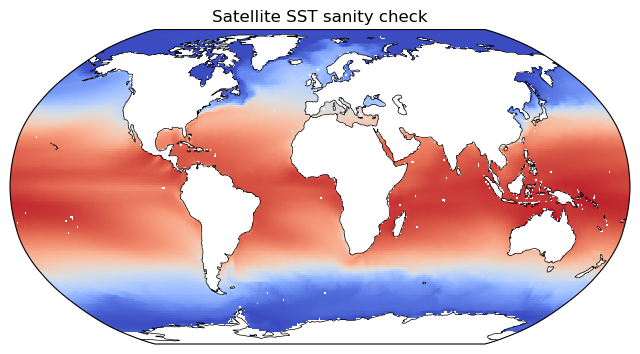

In [9]:
# rmv
sst_sample = ds_sat["tos"].isel(time=0).values

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()}, figsize=(8, 5))
ax.pcolormesh(ds_sat.lon.values, ds_sat.lat.values, sst_sample, transform=ccrs.PlateCarree(), cmap="coolwarm", shading="auto")
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.set_title("Satellite SST sanity check")
plt.show()

## 1. Preprocessing

### Train/val/test splits

Train/test split by CMIP6 model (leave on out)

Chronological train/validation split within training models

In [10]:
TRAIN_YEAR_BLOCKS = [(1850, 1996), (2025, 2100)]
VAL_YEAR_BLOCKS = [(1997, 2024)]
TEST_RECON_BLOCKS = [(1970, 2024)]
TEST_FULL_BLOCKS = [(1850, 2100)]

def subset_year_blocks(ds, year_blocks):
    years = np.array([t.year for t in ds.time.values])
    mask = np.zeros(ds.sizes["time"], dtype=bool)
    for start, end in year_blocks:
        mask |= (years >= start) & (years <= end)
    return ds.isel(time=mask)


def describe_split(name, ds):
        years = np.array([t.year for t in ds.time.values])
        print(f"{name}: {ds.sizes['time']} months | {years.min()}-{years.max()} | {len(np.unique(years))} years")
    
    
TRAIN_MODELS = [m for m in ALL_MODELS if m != TEST_MODEL and m in datasets]

assert TEST_MODEL in datasets, f"{TEST_MODEL} not loaded, cannot hold it out for testing."

print(f"Train models ({len(TRAIN_MODELS)}): {TRAIN_MODELS}")
print(f"Test model: {TEST_MODEL}")

test_dataset = datasets[TEST_MODEL]

test_dataset_full = subset_year_blocks(test_dataset, TEST_FULL_BLOCKS)
test_dataset_recon = subset_year_blocks(test_dataset, TEST_RECON_BLOCKS)

if RUN_MODE != "eval":
    train_split_datasets = {
        m: subset_year_blocks(datasets[m], TRAIN_YEAR_BLOCKS)
        for m in TRAIN_MODELS
    }

    val_split_datasets = {
        m: subset_year_blocks(datasets[m], VAL_YEAR_BLOCKS)
        for m in TRAIN_MODELS
    }
else:
    valsplitdatasets = {}

#
lats = test_dataset_recon.lat.values
lons = test_dataset_recon.lon.values

if RUN_MODE != "eval":
    for model_name in TRAIN_MODELS:
        describe_split(f"{model_name} train", train_split_datasets[model_name])
        describe_split(f"{model_name} val", val_split_datasets[model_name])

# for all modes
describe_split(f"{TEST_MODEL} test (reconstruction)", test_dataset_recon)
describe_split(f"{TEST_MODEL} test (full)", test_dataset_full)

Train models (0): []
Test model: UKESM1-0-LL
UKESM1-0-LL test (reconstruction): 660 months | 1970-2024 | 55 years
UKESM1-0-LL test (full): 3012 months | 1850-2100 | 251 years


### Input Stack

#### Define covariates and target variables

In [11]:
# Covariates
COVARIATE_VARS = [
    "tos", "tos_anom",
    "sos", "sos_anom",
    "chlos", "chlos_anom",
    "mlotst", "mlotst_anom",
]

# Target
TARGET_VAR = "pco2_residual"

print(f"Covariates from CMIP6 ({len(COVARIATE_VARS)} channels): {COVARIATE_VARS}")
print("+ atmospheric CO2 (1 channel) from input4mips")
print(f"Target: {TARGET_VAR}")

print(f"ds.time dtype: {type(ds.time.values[0])}")
print(f"ds_co2.time dtype: {type(ds_co2.time.values[0])}")

Covariates from CMIP6 (8 channels): ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom']
+ atmospheric CO2 (1 channel) from input4mips
Target: pco2_residual
ds.time dtype: <class 'cftime._cftime.Datetime360Day'>
ds_co2.time dtype: <class 'numpy.datetime64'>


#### Add atmospheric CO2 from input4mips

In [12]:
CO2_VAR = "mole_fraction_of_carbon_dioxide_in_air"

print(f"ds.time dtype: {type(ds.time.values[0])}")
print(f"ds_co2.time dtype: {type(ds_co2.time.values[0])}")
# different, need match!

def to_year_month_cftime(time_values):
    """For cftime objects (CMIP6 model time) - .year/.month work directly."""
    return [(t.year, t.month) for t in time_values]

def to_year_month_numpy(time_values):
    """For numpy.datetime64 (CO2 dataset time) - convert via pandas Timestamp."""
    return [(pd.Timestamp(t).year, pd.Timestamp(t).month) for t in time_values]

ds_ym  = to_year_month_cftime(ds.time.values)
co2_ym = to_year_month_numpy(ds_co2.time.values)

co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

# check for any missing matches before indexing
missing = [ym for ym in ds_ym if ym not in co2_lookup]
if missing:
    print(f"WARNING: {len(missing)} CMIP6 timesteps have no matching CO2 month")
    print(f"First few missing: {missing[:5]}")
else:
    print("All CMIP6 timesteps found a matching CO2 month.")

co2_indices = [co2_lookup[ym] for ym in ds_ym]

co2_data = ds_co2[CO2_VAR]
print(f"Before dropping bounds: {co2_data.dims}")

# select index 0 along bound/bnds dims to collapse them
if "bound" in co2_data.dims:
    co2_data = co2_data.isel(bound=0, drop=True)
if "bnds" in co2_data.dims:
    co2_data = co2_data.isel(bnds=0, drop=True)

print(f"After dropping bounds: {co2_data.dims}")
print(f"Shape: {co2_data.shape}")

co2_indices = [co2_lookup[ym] for ym in ds_ym]

# now align to CMIP6 time using isel
co2_aligned_da = co2_data.isel(time=co2_indices)
print(f"\nCO2 aligned dims: {co2_aligned_da.dims}")
print(f"CO2 aligned shape: {co2_aligned_da.shape}")

# co2_aligned_values = co2_aligned_da.values
co2_aligned_values = co2_aligned_da.transpose("time", "lat", "lon").values # to match cmip order
print(f"CO2 sample value: {co2_aligned_values[0].mean():.2f} ppm")

ds.time dtype: <class 'cftime._cftime.Datetime360Day'>
ds_co2.time dtype: <class 'numpy.datetime64'>
All CMIP6 timesteps found a matching CO2 month.
Before dropping bounds: ('time', 'lat', 'lon')
After dropping bounds: ('time', 'lat', 'lon')
Shape: (3012, 180, 360)

CO2 aligned dims: ('time', 'lat', 'lon')
CO2 aligned shape: (3012, 180, 360)


CO2 sample value: 285.22 ppm


### Build the input stack tensor

We stack the covariates along a new "channel" dimension with shape (time, channel, lat, lon)

In [13]:
def extract_months(time_values):
    # to work for both cmip and satellite - either cftime or np.datetime64
    first = time_values[0]
    if hasattr(first, "month"): # cftime attribute
        return np.array([t.month for t in time_values], dtype=np.float32)
    return np.array([pd.Timestamp(t).month for t in time_values], dtype=np.float32)

def add_month_cyclical_channels(ds, input_stack):
    """
    Add two extra input channels month_sin and month_cos 
    for modle to learn seasonality ina cyclical way
    """
    months = extract_months(ds.time.values) # calendar month for each time step - (time,)
    x = 2 * np.pi * (months-1) / 12.0 # convert month number into an angle on unit circle - 1 ... 12 -> 0 .. 2pi
    # https://medium.com/@indradeep.chatterjee/cyclic-encoding-in-machine-learning-a-practical-guide-with-code-and-intuition-049846419ccb

    # turn 1D month into 4D tensors (time, 1, 1, 1) with singleton dimensions 
    # so to broadcast (not copy) across spatial grid
    sin_m = np.sin(x).astype(np.float32)[:, None, None, None]
    cos_m = np.cos(x).astype(np.float32)[:, None, None, None]

    # input_stack shape (time, channels, lat, lon)
    # want one motnh value per time step repeated across every lat/lon cell
    sin_ch = np.broadcast_to(sin_m, (input_stack.shape[0], 1, input_stack.shape[2], input_stack.shape[3]))
    cos_ch = np.broadcast_to(cos_m, (input_stack.shape[0], 1, input_stack.shape[2], input_stack.shape[3]))

    # concatenate new channels to existing input stack
    # (time, og_channels, lat, lon) --> (time, og_channels+2, lat, lon)
    return np.concatenate([input_stack, sin_ch, cos_ch], axis=1), ["month_sin", "month_cos"] # include channel names

In [14]:
def build_input_target_stack(ds, ds_co2, COVARIATE_VARS, TARGET_VAR):
    """
    Runs the CO2 alignment + covariate stacking logic for a single model's dataset.
    Returns:
        input_stack: (time, channel, lat, lon)
        target_stack: (time, 1, lat, lon)
        all_covariate_names: list of channel names
    """

    print("Building input stack...")

    ds_ym = to_year_month_cftime(ds.time.values)
    co2_ym = to_year_month_numpy(ds_co2.time.values)
    co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

    missing = [ym for ym in ds_ym if ym not in co2_lookup]
    if missing:
        raise ValueError(f"{len(missing)} timesteps have no matching CO2 month: {missing[:5]}")

    co2_indices = [co2_lookup[ym] for ym in ds_ym]
    co2_data = ds_co2[CO2_VAR]

    if "bound" in co2_data.dims:
        co2_data = co2_data.isel(bound=0, drop=True)
        print("dropping bound")
    if "bnds" in co2_data.dims:
        co2_data = co2_data.isel(bnds=0, drop=True)
        print("dropping bnds")

    co2_aligned_da = co2_data.isel(time=co2_indices)
    co2_aligned_values = co2_aligned_da.transpose("time", "lat", "lon").values.astype(np.float32) # float 32

    covariate_arrays = [ds[var].values.astype(np.float32) for var in COVARIATE_VARS] # float 32
    all_arrays = covariate_arrays + [co2_aligned_values]
    
    input_stack = np.stack(all_arrays, axis=1).astype(np.float32)  # (time, channel, lat, lon) - float 32
    input_stack, month_names = add_month_cyclical_channels(ds, input_stack)

    target_stack = ds[TARGET_VAR].values[:, np.newaxis].astype(np.float32) # float 32
    target_stack = ds[TARGET_VAR].values.astype(np.float32)
    if target_stack.ndim == 3:
        target_stack = target_stack[:, np.newaxis, :, :]
    elif target_stack.ndim == 2:
        target_stack = target_stack[np.newaxis, np.newaxis, :, :]

    all_covariate_names = COVARIATE_VARS + ["co2_atm"] + month_names

    print(f"   Input stack shape:  {input_stack.shape}")
    print(f"   Target stack shape: {target_stack.shape}")
    print(f"   Channels: {all_covariate_names}")
    print(f"   Input NaN fraction:  {np.isnan(input_stack).mean():.3f}")
    print(f"   Target NaN fraction: {np.isnan(target_stack).mean():.3f}")

    return input_stack, target_stack, all_covariate_names

In [15]:
def extract_thermal_stack(ds):
    """
    Extracts pre-computed thermal pCO2 component (uatm) from CMIP6 notebook save
    Aligned to ds.time with shape (time, 1, lat, lon) to match residual target stack.
    """
    thermal_stack = ds["pco2_thermal"].values[:, np.newaxis].astype(np.float32)
    return thermal_stack

In [16]:
print("Building input stacks...")

if RUN_MODE != "eval":
    train_inputs, train_targets = [], []
    for model_name, model_ds in train_split_datasets.items():
        print(f"TRAIN stack: {model_name}")
        x, y, all_covariate_names = build_input_target_stack(model_ds, ds_co2, COVARIATE_VARS, TARGET_VAR)
        train_inputs.append(x)
        train_targets.append(y)
    
    train_input_stack = np.concatenate(train_inputs, axis=0)
    train_target_stack = np.concatenate(train_targets, axis=0)

    val_inputs, val_targets = [], []
    for model_name, model_ds in val_split_datasets.items():
        print(f"VAL stack: {model_name}")
        x, y, all_covariate_names = build_input_target_stack(model_ds, ds_co2, COVARIATE_VARS, TARGET_VAR)
        val_inputs.append(x)
        val_targets.append(y)

    val_input_stack = np.concatenate(val_inputs, axis=0)
    val_target_stack = np.concatenate(val_targets, axis=0)

print(f"TEST reconstruction stack: {TEST_MODEL}")
test_recon_input_stack, test_recon_target_stack, all_covariate_names = build_input_target_stack(
    test_dataset_recon, ds_co2, COVARIATE_VARS, TARGET_VAR
)

print(f"TEST full-period stack: {TEST_MODEL}")
test_full_input_stack, test_full_target_stack, all_covariate_names = build_input_target_stack(
    test_dataset_full, ds_co2, COVARIATE_VARS, TARGET_VAR
)

Building input stacks...
TEST reconstruction stack: UKESM1-0-LL
Building input stack...


   Input stack shape:  (660, 11, 180, 360)
   Target stack shape: (660, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm', 'month_sin', 'month_cos']


   Input NaN fraction:  0.263
   Target NaN fraction: 0.362
TEST full-period stack: UKESM1-0-LL
Building input stack...


   Input stack shape:  (3012, 11, 180, 360)
   Target stack shape: (3012, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm', 'month_sin', 'month_cos']


   Input NaN fraction:  0.263
   Target NaN fraction: 0.362


In [17]:
test_recon_thermal_stack = extract_thermal_stack(test_dataset_recon)
test_full_thermal_stack  = extract_thermal_stack(test_dataset_full)

print(f"Test reconstruction thermal stack shape: {test_recon_thermal_stack.shape}")
print(f"Test full-period thermal stack shape: {test_full_thermal_stack.shape}")
print(f"Reconstruction thermal NaN fraction: {np.isnan(test_recon_thermal_stack).mean():.3f}")
print(f"Full-period thermal NaN fraction: {np.isnan(test_full_thermal_stack).mean():.3f}")

Test reconstruction thermal stack shape: (660, 1, 180, 360)
Test full-period thermal stack shape: (3012, 1, 180, 360)
Reconstruction thermal NaN fraction: 0.362


Full-period thermal NaN fraction: 0.362


### Replace NaNs (land cells) with 0 and track a land mask

In [18]:
# train_land_mask = np.isnan(train_target_stack)
# val_land_mask = np.isnan(val_target_stack)
# test_land_mask = np.isnan(test_target_stack)

def build_combined_mask(input_stack, target_stack):
    """
    Combines NaN locations across all input channels and the target into a single
    (time, 1, lat, lon) land/invalid mask. A cell is masked if ANY channel (including
    target) is NaN there, so covariate-only NaNs can't leak into training as fake zeros.
    """
    input_nan_any = np.isnan(input_stack).any(axis=1, keepdims=True)  # (time, 1, lat, lon)
    target_nan = np.isnan(target_stack)  # (time, 1, lat, lon)
    return input_nan_any | target_nan

if RUN_MODE != "eval":
    train_land_mask = build_combined_mask(train_input_stack, train_target_stack)
    val_land_mask = build_combined_mask(val_input_stack, val_target_stack)

    # mutate in place
    np.nan_to_num(train_input_stack, copy=False, nan=0.0)
    np.nan_to_num(train_target_stack, copy=False, nan=0.0)

    np.nan_to_num(val_input_stack, copy=False, nan=0.0)
    np.nan_to_num(val_target_stack, copy=False, nan=0.0)

    np.nan_to_num(test_recon_thermal_stack, copy=False, nan=0.0)
    np.nan_to_num(test_full_thermal_stack, copy=False, nan=0.0)
    # no need for new mask - same as before

    print(f"Train land mask fraction: {train_land_mask.mean():.3f}")
    print(f"Val land mask fraction: {val_land_mask.mean():.3f}")

    # sanity check: per-channel NaN fraction vs combined mask fraction
    per_channel_nan_frac = np.isnan(train_input_stack).mean(axis=(0, 2, 3))
    print(f"Per-channel NaN fraction (train input): {per_channel_nan_frac}")
    print(f"Target-only NaN fraction (train): {np.isnan(train_target_stack).mean():.3f}")
    print(f"Combined mask fraction (train): {train_land_mask.mean():.3f}")

test_recon_land_mask = build_combined_mask(test_recon_input_stack, test_recon_target_stack)
test_full_land_mask = build_combined_mask(test_full_input_stack, test_full_target_stack)

# mutate in place
np.nan_to_num(test_recon_input_stack, copy=False, nan=0.0)
np.nan_to_num(test_recon_target_stack, copy=False, nan=0.0)

np.nan_to_num(test_full_input_stack, copy=False, nan=0.0)
np.nan_to_num(test_full_target_stack, copy=False, nan=0.0)

print(f"Test reconstruction land mask fraction: {test_recon_land_mask.mean():.3f}")
print(f"Test full-period land mask fraction: {test_full_land_mask.mean():.3f}")

Test reconstruction land mask fraction: 0.363
Test full-period land mask fraction: 0.363


### Normalise (0 mean, 1 variance per channel)

For stable training and reducing CMIP6/satellite covariate distribution mismatch

In [19]:
def apply_normalisation(stack, means, stds):
    """ In-place normalisation"""
    for c in range(stack.shape[1]):
        stack[:, c] -= means[c]
        stack[:, c] /= (stds[c] + 1e-8)
    return stack

def normalise_stack(stack, mask):
    """
    Computes per-channel mean/std over ocean cells only (mask marks land/NaN cells to exclude),
    then applies normalisation. Returns (normalized_stack, means, stds).
    """
    n_channels = stack.shape[1]
    means = np.zeros(n_channels, dtype=np.float32)
    stds = np.zeros(n_channels, dtype=np.float32)

    ocean_mask = ~mask  # mask is True over land; invert to get valid ocean cells
    # mask has shape (time, 1, lat, lon) - broadcast against each channel
    ocean_mask_b = np.broadcast_to(ocean_mask, stack.shape)

    for c in range(n_channels):
        valid_vals = stack[:, c][ocean_mask_b[:, c]]
        means[c] = valid_vals.mean()
        stds[c] = valid_vals.std()

    apply_normalisation(stack, means, stds) # no copy
    return stack, means, stds


if RUN_MODE == "train":
    train_input_norm, input_means, input_stds = normalise_stack(train_input_stack, mask=train_land_mask)
    train_target_norm, target_means, target_stds = normalise_stack(train_target_stack, mask=train_land_mask)

    val_input_norm = apply_normalisation(val_input_stack.copy(), input_means, input_stds)
    val_target_norm = apply_normalisation(val_target_stack.copy(), target_means, target_stds)

elif RUN_MODE in ["eval", "resume"]:
    if RUN_MODE == "resume":
        train_input_norm = apply_normalisation(train_input_stack.copy(), input_means, input_stds)
        train_target_norm = apply_normalisation(train_target_stack.copy(), target_means, target_stds)
        val_input_norm = apply_normalisation(val_input_stack.copy(), input_means, input_stds)
        val_target_norm = apply_normalisation(val_target_stack.copy(), target_means, target_stds)

# ow should exist from checkpoints
test_recon_input_norm = apply_normalisation(test_recon_input_stack.copy(), input_means, input_stds)
test_recon_target_norm = apply_normalisation(test_recon_target_stack.copy(), target_means, target_stds)

test_full_input_norm = apply_normalisation(test_full_input_stack.copy(), input_means, input_stds)
test_full_target_norm = apply_normalisation(test_full_target_stack.copy(), target_means, target_stds)

print(f"Input means (from TRAIN only): {input_means}")
print(f"Target mean: {target_means[0]:.2f}, std: {target_stds[0]:.2f}")

Input means (from TRAIN only): [ 1.45073185e+01 -6.02230243e-03  3.40075912e+01  2.82107596e-03
  2.49137491e-01 -7.12623587e-05  5.70151901e+01  8.63934681e-02
  3.85232758e+02 -1.49928585e-08  8.35101499e-09]
Target mean: -1.39, std: 97.97


### Convert to PyTorch tensors

In [20]:
# assert train_input_norm.dtype == np.float32 # so no need to call .float() on all below - is ok
BATCH_SIZE = 32 if IS_HPC else 4

test_recon_input_tensor = torch.from_numpy(test_recon_input_norm)
test_recon_target_tensor = torch.from_numpy(test_recon_target_norm)

test_full_input_tensor = torch.from_numpy(test_full_input_norm)
test_full_target_tensor = torch.from_numpy(test_full_target_norm)

print(f"Test reconstruction tensor:  {test_recon_input_tensor.shape}")
print(f"Test full-period tensor:  {test_full_input_tensor.shape}")

if RUN_MODE in ["train", "resume"]:
    train_input_tensor = torch.from_numpy(train_input_norm)
    train_target_tensor = torch.from_numpy(train_target_norm)
    print(f"Train tensor: {train_input_tensor.shape}")

    val_input_tensor = torch.from_numpy(val_input_norm)
    val_target_tensor = torch.from_numpy(val_target_norm)
    print(f"Val tensor: {val_input_tensor.shape}")

    batch_idx = torch.randperm(train_input_tensor.shape[0])[:BATCH_SIZE]
    input_batch = train_input_tensor[batch_idx].to(DEVICE)
    target_batch = train_target_tensor[batch_idx].to(DEVICE)
    land_mask_batch = torch.from_numpy(train_land_mask[batch_idx]).bool().to(DEVICE)

    print("Batch size =", BATCH_SIZE)
    print(f"Batch shapes - input: {input_batch.shape}, target: {target_batch.shape}")
    
    print(f"Batch shapes - input: {input_batch.shape}, target: {target_batch.shape}")

Test reconstruction tensor:  torch.Size([660, 11, 180, 360])
Test full-period tensor:  torch.Size([3012, 11, 180, 360])


### Satellite covariate inference stack

In [21]:
if USE_SATELLITE:
    def build_satellite_input_stack(ds_sat, ds_co2, covariate_vars):
        """
        Build satellite covariate input stack with the same channel order use
        in CMIP6 training: N environmental covariates + atmospheric CO2

        Returns
        -------
        sat_input_stack : np.ndarray
            Shape (time, channel, lat, lon)
        sat_cov_names : list[str]
            Channel names in stack order
        """
        print("Building satellite input stack...")

        sat_ym = to_year_month_numpy(ds_sat.time.values)
        co2_ym = to_year_month_numpy(ds_co2.time.values)
        co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

        missing = [ym for ym in sat_ym if ym not in co2_lookup]
        if missing:
            raise ValueError(f"{len(missing)} satellite months have no matching CO2 month, first few: {missing[:5]}")

        co2_data = ds_co2[CO2_VAR]

        if "bound" in co2_data.dims:
            co2_data = co2_data.isel(bound=0, drop=True)
            print("dropped bound dim, new dims:", co2_data.dims)
        if "bnds" in co2_data.dims:
            co2_data = co2_data.isel(bnds=0, drop=True)
            print("dropped bnds dim, new dims:", co2_data.dims)

        co2_indices = [co2_lookup[ym] for ym in sat_ym]
        co2_aligned = co2_data.isel(time=co2_indices).transpose("time", "lat", "lon").values.astype(np.float32)

        covariate_arrays = [ds_sat[var].values.astype(np.float32) for var in covariate_vars]
        all_arrays = covariate_arrays + [co2_aligned]

        sat_input_stack = np.stack(all_arrays, axis=1).astype(np.float32)
        sat_input_stack, month_names = add_month_cyclical_channels(ds_sat, sat_input_stack)
        sat_cov_names = list(covariate_vars) + ["co2_atm"] + month_names

        print("Satellite input stack shape", sat_input_stack.shape)
        print("Satellite channels", sat_cov_names)
        print("Satellite input NaN fraction", f"{np.isnan(sat_input_stack).mean():.3f}")

        return sat_input_stack, sat_cov_names

    sat_input_stack, sat_all_covariate_names = build_satellite_input_stack(ds_sat, ds_co2, SAT_COVARIATE_VARS)
    sat_full_land_mask = np.isnan(sat_input_stack).any(axis=1, keepdims=True) # build invalid mask from any NaN in any input channel - no target, input only
    np.nan_to_num(sat_input_stack, copy=False, nan=0.0) # fill NaNs with 0 before normalisation like training
    sat_input_norm = apply_normalisation(sat_input_stack, input_means, input_stds) # normalise with TRAIN CMIP6 statistics only - dont recompute on satellite data

    print("Satellite land/invalid mask fraction", f"{sat_full_land_mask.mean():.3f}")
    print("Satellite input after nan_to_num, any NaN remaining?", np.isnan(sat_input_stack).any())
    print("Satellite normalised stack shape", sat_input_norm.shape)
    print("Satellite normalised dtype", sat_input_norm.dtype)

    # build overlap-only stack for comparison/diagnostics
    sat_input_stack_overlap, satcovnames_overlap = build_satellite_input_stack(ds_sat_overlap, ds_co2, SAT_COVARIATE_VARS)
    sat_overlap_land_mask = np.isnan(sat_input_stack_overlap).any(axis=1, keepdims=True)
    np.nan_to_num(sat_input_stack_overlap, copy=False, nan=0.0)
    sat_input_norm_overlap = apply_normalisation(sat_input_stack_overlap, input_means, input_stds)

    print("Overlap satellite land/invalid mask fraction:", f"{sat_overlap_land_mask.mean():.3f}")
    print("Overlap satellite input after nan_to_num, any NaN remaining?", np.isnan(sat_input_stack_overlap).any())
    print("Overlap satellite normalised stack shape:", sat_input_norm_overlap.shape)
    print("Overlap satellite normalised dtype:", sat_input_norm_overlap.dtype)

Building satellite input stack...


Satellite input stack shape (660, 11, 180, 360)
Satellite channels ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm', 'month_sin', 'month_cos']


Satellite input NaN fraction 0.280


Satellite land/invalid mask fraction 0.492


Satellite input after nan_to_num, any NaN remaining? False
Satellite normalised stack shape (660, 11, 180, 360)
Satellite normalised dtype float32
Building satellite input stack...


Satellite input stack shape (328, 11, 180, 360)
Satellite channels ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm', 'month_sin', 'month_cos']


Satellite input NaN fraction 0.286


Overlap satellite land/invalid mask fraction: 0.523
Overlap satellite input after nan_to_num, any NaN remaining? False
Overlap satellite normalised stack shape: (328, 11, 180, 360)
Overlap satellite normalised dtype: float32


## 2. Simple CNN Model

In [22]:
class MinimalCNN(nn.Module):
    """
    Tiny CNN: input stack -> single-channel output, same size.
    Just to confirm tensors
    """
    def __init__(self, in_channels, hidden_channels=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, hidden_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_channels, hidden_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_channels, 1, kernel_size=3, padding=1),
        )

    def forward(self, x):
        return self.net(x)

### Training loop

In [23]:
def masked_mse(output, target, land_mask):
    ocean_mask = ~land_mask
    return ((output[ocean_mask] - target[ocean_mask]) ** 2).mean()

def iterate_batches(inputs, targets, land_mask, batch_size, shuffle=True):
    n = inputs.shape[0]
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        b = idx[start:start + batch_size]
        yield (inputs[b].to(DEVICE), targets[b].to(DEVICE),
               torch.from_numpy(land_mask[b]).bool().to(DEVICE))

In [24]:
model = MinimalCNN(in_channels=len(all_covariate_names)).to(DEVICE)
criterion = masked_mse
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

if DO_TRAIN:
    history = {"train_loss": [], "val_loss": []}
    start_epoch = 0
    best_val_loss = np.inf

    N_EPOCHS = 20 if IS_HPC else 2

    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        running_loss, n_batches = 0.0, 0

        for xb, yb, mb in iterate_batches(train_input_tensor, train_target_tensor, train_land_mask, BATCH_SIZE, shuffle=True):
            optimizer.zero_grad()
            output = model(xb)
            loss = criterion(output, yb, mb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            n_batches += 1

        train_loss = running_loss / max(n_batches, 1)  # avoid division by zero

        model.eval()
        val_running_loss, val_batches = 0.0, 0
        with torch.no_grad():
            for xb, yb, mb in iterate_batches(val_input_tensor, val_target_tensor, val_land_mask, BATCH_SIZE, shuffle=False):
                output = model(xb)
                val_running_loss += criterion(output, yb, mb).item()
                val_batches += 1

        val_loss = val_running_loss / max(val_batches, 1)  # avoid division by zero

        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))

        last_checkpoint = {
            "epoch": int(epoch + 1),
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "best_val_loss": float(best_val_loss),
            "history": {
                "train_loss": list(history["train_loss"]),
                "val_loss": list(history["val_loss"]),
            },
            "covariates": list(all_covariate_names),
            "test_model": str(TEST_MODEL),
            "input_means": np.asarray(input_means, dtype=np.float32),
            "input_stds": np.asarray(input_stds, dtype=np.float32),
            "target_means": np.asarray(target_means, dtype=np.float32),
            "target_stds": np.asarray(target_stds, dtype=np.float32),
        }
        torch.save(last_checkpoint, last_model_path)
        torch.save(last_checkpoint, os.path.join(CHECKPOINT_DIR, f"baseline_cnn_last_{RUN_TIMESTAMP}.pt"))

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_checkpoint = {
                "epoch": int(epoch + 1),
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": float(train_loss),
                "val_loss": float(val_loss),
                "best_val_loss": float(best_val_loss),
                "history": {
                    "train_loss": list(history["train_loss"]),
                    "val_loss": list(history["val_loss"]),
                },
                "covariates": list(all_covariate_names),
                "test_model": str(TEST_MODEL),
                "input_means": np.asarray(input_means, dtype=np.float32),
                "input_stds": np.asarray(input_stds, dtype=np.float32),
                "target_means": np.asarray(target_means, dtype=np.float32),
                "target_stds": np.asarray(target_stds, dtype=np.float32),
            }
            torch.save(best_checkpoint, best_model_path)
            torch.save(best_checkpoint, os.path.join(CHECKPOINT_DIR, f"baseline_cnn_best_{RUN_TIMESTAMP}.pt"))
            print(f"  Saved new best model to {best_model_path}")

        print(f"Epoch {epoch+1}/{N_EPOCHS} - train_loss: {train_loss:.4f}, val_loss: {val_loss:.4f}")

else:
    print("Skipping training because RUN_MODE='eval'.")

Skipping training because RUN_MODE='eval'.


Loss history lengths - train: 20, val: 20


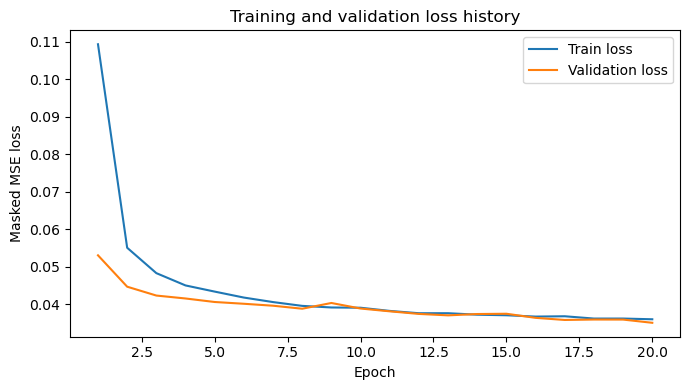

In [25]:
def plot_loss_history(history):
    train_hist = history.get("train_loss", [])
    val_hist = history.get("val_loss", [])

    if len(train_hist) == 0 and len(val_hist) == 0:
        print("No saved training history found in checkpoint.")
        return

    print(f"Loss history lengths - train: {len(train_hist)}, val: {len(val_hist)}")

    plt.figure(figsize=(7, 4))
    plt.plot(np.arange(1, len(train_hist)+1), train_hist, label='Train loss')
    plt.plot(np.arange(1, len(val_hist)+1), val_hist, label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Masked MSE loss')
    plt.title('Training and validation loss history')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_loss_history(history)

In [26]:
history_npz_path = os.path.join(CHECKPOINT_DIR, f"baseline_loss_history_{RUN_TIMESTAMP}.npz")
np.savez(
    history_npz_path,
    train_loss=np.array(history["train_loss"]),
    val_loss=np.array(history["val_loss"]),
)
print(f"Saved loss history to {history_npz_path}")

Saved loss history to /rds/general/user/efs25/home/irp-efs25/checkpoints/baseline_loss_history_20260812_194917.npz


### Forward pass

In [27]:
# checkpoint = torch.load(best_model_path, map_location=DEVICE, weights_only=False)
checkpoint = load_checkpoint_with_history(best_model_path)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded best model from epoch {checkpoint['epoch']} with val_loss={checkpoint['val_loss']:.4f}")

Loaded best model from epoch 20 with val_loss=0.0351


### Test loss

In [28]:
def evaluate_split(model, inputs, targets, land_mask, batch_size, split_name):
    model.eval()
    running_loss = 0.0
    n_batches = 0
    last_output = None
    last_target = None
    last_mask = None

    with torch.no_grad():
        for xb, yb, mb in iterate_batches(
            inputs, targets, land_mask, batch_size, shuffle=False
        ):
            output = model(xb)
            loss = criterion(output, yb, mb)

            running_loss += loss.item()
            n_batches += 1

            last_output = output.detach().cpu()
            last_target = yb.detach().cpu()
            last_mask = mb.detach().cpu()

    loss_value = running_loss / max(n_batches, 1)
    print(f"{split_name} loss: {loss_value:.4f}")

    if last_output is not None:
        print(f"{split_name} output shape: {tuple(last_output.shape)}")
        print(f"{split_name} target shape: {tuple(last_target.shape)}")
        print(f"{split_name} shapes match: {tuple(last_output.shape) == tuple(last_target.shape)}")
        print(
            f"{split_name} output stats: "
            f"mean={last_output.mean().item():.4f}, "
            f"std={last_output.std().item():.4f}"
        )
        print(f"{split_name} output has NaN: {torch.isnan(last_output).any().item()}")
        print(f"{split_name} output has Inf: {torch.isinf(last_output).any().item()}")

    return {
        "loss": loss_value,
        "last_output": last_output,
        "last_target": last_target,
        "last_mask": last_mask,
    }

print(f"Evaluation RUN_MODE = {RUN_MODE}")

if RUN_MODE != "eval":
    val_eval = evaluate_split(
        model,
        val_input_tensor,
        val_target_tensor,
        val_land_mask,
        BATCH_SIZE,
        "Validation",
    )
    val_loss_eval = val_eval["loss"]
else: 
    print("Skipping validation split because RUN_MODE == 'eval'")
    val_eval = None
    val_loss_eval = None


test_recon_eval = evaluate_split(
    model,
    test_recon_input_tensor,
    test_recon_target_tensor,
    test_recon_land_mask,
    BATCH_SIZE,
    f"Test ({TEST_MODEL}, 1970-2024)",
)

test_full_eval = evaluate_split(
    model,
    test_full_input_tensor,
    test_full_target_tensor,
    test_full_land_mask,
    BATCH_SIZE,
    f"Test ({TEST_MODEL}, 1850-2100)",
)

test_recon_loss = test_recon_eval["loss"]
test_full_loss = test_full_eval["loss"]

Evaluation RUN_MODE = eval
Skipping validation split because RUN_MODE == 'eval'


Test (UKESM1-0-LL, 1970-2024) loss: 0.0501
Test (UKESM1-0-LL, 1970-2024) output shape: (20, 1, 180, 360)
Test (UKESM1-0-LL, 1970-2024) target shape: (20, 1, 180, 360)
Test (UKESM1-0-LL, 1970-2024) shapes match: True
Test (UKESM1-0-LL, 1970-2024) output stats: mean=0.2470, std=0.3093
Test (UKESM1-0-LL, 1970-2024) output has NaN: False
Test (UKESM1-0-LL, 1970-2024) output has Inf: False


Test (UKESM1-0-LL, 1850-2100) loss: 0.0513
Test (UKESM1-0-LL, 1850-2100) output shape: (4, 1, 180, 360)
Test (UKESM1-0-LL, 1850-2100) target shape: (4, 1, 180, 360)
Test (UKESM1-0-LL, 1850-2100) shapes match: True
Test (UKESM1-0-LL, 1850-2100) output stats: mean=1.8616, std=0.3328
Test (UKESM1-0-LL, 1850-2100) output has NaN: False
Test (UKESM1-0-LL, 1850-2100) output has Inf: False


### Helper functions

In [29]:
def denormalise(x, mean, std):
    return x * std + mean

def predict_in_batches(model, input_tensor, batch_size):
    model.eval()
    n = input_tensor.shape[0]
    preds = np.empty((n, 1, input_tensor.shape[2], input_tensor.shape[3]), dtype=np.float32)
    
    with torch.no_grad():
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            xb = input_tensor[start:end].to(DEVICE)
            out = model(xb).detach().cpu().numpy().astype(np.float32)
            preds[start:end] = out
            del xb, out  # free memory
            
    return preds

def masked_flatten(data, ocean_mask):
    flat = data[ocean_mask]
    return flat[np.isfinite(flat)]

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    bias = np.mean(y_pred - y_true)

    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        corr = np.corrcoef(y_true, y_pred)[0, 1]
    else:
        corr = np.nan

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "Corr": float(corr),
        "Bias": float(bias),
    }


def summarise_distribution(name, arr):
    arr = np.asarray(arr)
    arr = arr[np.isfinite(arr)]

    stats = {
        "min": float(np.min(arr)),
        "max": float(np.max(arr)),
        "mean": float(np.mean(arr)),
        "std": float(np.std(arr)),
        "median": float(np.median(arr)),
        "q01": float(np.quantile(arr, 0.01)),
        "q05": float(np.quantile(arr, 0.05)),
        "q95": float(np.quantile(arr, 0.95)),
        "q99": float(np.quantile(arr, 0.99)),
    }

    print(
        f"{name}: "
        f"min={stats['min']:.2f}, max={stats['max']:.2f}, "
        f"mean={stats['mean']:.2f}, std={stats['std']:.2f}, "
        f"median={stats['median']:.2f}, "
        f"q01={stats['q01']:.2f}, q05={stats['q05']:.2f}, "
        f"q95={stats['q95']:.2f}, q99={stats['q99']:.2f}"
    )
    return stats

def masked_mean_map(data, land_mask):
    data = np.asarray(data)
    mask = np.asarray(land_mask)

    if data.ndim == 4:
        field = data[:, 0, :, :]
    elif data.ndim == 3:
        field = data
    elif data.ndim == 2:
        field = data[None, :, :]
    else:
        raise ValueError(f"Unexpected data shape: {data.shape}")

    if mask.ndim == 4:
        ocean = mask[:, 0, :, :] == 0
    elif mask.ndim == 3 or mask.ndim == 2:
        ocean = mask == 0
    else:
        raise ValueError(f"Unexpected mask shape: {mask.shape}")

    masked = np.where(ocean, field, np.nan)
    
    return np.nanmean(masked, axis=0)
    # # masked = np.where(land_mask[:, 0], np.nan, data[:, 0])
    # # return np.nanmean(masked, axis=0)
    # field = data[:, 0] if data.ndim==4 else data
    # masked = np.where(land_mask>0, np.nan, field)
    # count = np.sum(np.isfinite(masked), axis=0)
    # out = np.full(masked.shape[1:], np.nan, dtype=np.float32)
    # np.divide(np.nansum(masked, axis=0), count, out=out, where=count>0)

    # return out

### Satellite inference

In [30]:
if USE_SATELLITE:
    #  Full satellite 1970-2024
    sat_input_tensor_full = torch.from_numpy(sat_input_stack) # convert to tensor
    sat_full_pred_norm = predict_in_batches(model, sat_input_tensor_full, BATCH_SIZE)
    sat_full_pred_resid = denormalise(sat_full_pred_norm, target_means[0], target_stds[0])
    
    print("Full satellite tensor", sat_input_tensor_full.shape)
    print("Full satellite prediction shape", sat_full_pred_resid.shape)
    print("Full satellite prediction has NaN?", np.isnan(sat_full_pred_resid).any())
    print("Full satellite prediction has Inf?", np.isinf(sat_full_pred_resid).any())
 
    # Overlap satellite 1997-024
    sat_input_tensor_overlap = torch.from_numpy(sat_input_stack_overlap)
    sat_overlap_pred_norm = predict_in_batches(model, sat_input_tensor_overlap, BATCH_SIZE)
    sat_overlap_pred_resid = denormalise(sat_overlap_pred_norm, target_means[0], target_stds[0])

    print("Overlap satellite tensor", sat_input_tensor_overlap.shape)
    print("Overlap satellite prediction shape", sat_overlap_pred_resid.shape)
    print("Overlap satellite prediction has NaN?", np.isnan(sat_overlap_pred_resid).any())
    print("Overlap satellite prediction has Inf?", np.isinf(sat_overlap_pred_resid).any())
        
    # sat_ocean = ~sat_full_land_mask[:, 0]
    # sat_pred_flat = masked_flatten(sat_pred_resid[:, 0], sat_ocean)
    # # summarise distr in next cell
    # sat_npz_time = np.array(ds_sat.time.values).astype("datetime64[ns]")

    sat_ocean_full = ~sat_full_land_mask[:, 0]
    sat_pred_flat_full = masked_flatten(sat_full_pred_resid[:, 0], sat_ocean_full)
    sat_full_time = np.array(ds_sat.time.values).astype("datetime64[ns]")

    sat_ocean_overlap = ~sat_overlap_land_mask[:, 0]
    sat_pred_flat_overlap = masked_flatten(sat_overlap_pred_resid[:, 0], sat_ocean_overlap)
    sat_overlap_time = np.array(ds_sat_overlap.time.values).astype("datetime64[ns]")

    print("\nSatellite distribution stats")
    summarise_distribution("Satellite full prediction", sat_pred_flat_full)
    summarise_distribution("Satellite overlap prediction", sat_pred_flat_overlap)

Full satellite tensor torch.Size([660, 11, 180, 360])
Full satellite prediction shape (660, 1, 180, 360)
Full satellite prediction has NaN? False
Full satellite prediction has Inf? False


Overlap satellite tensor torch.Size([328, 11, 180, 360])
Overlap satellite prediction shape (328, 1, 180, 360)
Overlap satellite prediction has NaN? False
Overlap satellite prediction has Inf? False

Satellite distribution stats


Satellite full prediction: min=-689.14, max=156.40, mean=-24.78, std=31.69, median=-26.02, q01=-110.35, q05=-72.66, q95=25.96, q99=41.35


Satellite overlap prediction: min=-689.14, max=156.40, mean=-3.50, std=26.47, median=-2.16, q01=-87.50, q05=-46.99, q95=34.07, q99=47.02


In [31]:
if USE_SATELLITE:
    # Expand a true 12-value monthly climatology (dimension "month", size 12)
    # onto an arbitrary target time axis. Only used for sst_clim below, since
    # ds_tak's fields are already expanded onto their own full time axis.
    def monthly_clim_to_time(clim_da, target_time):
        month_idx = xr.DataArray(
            pd.DatetimeIndex(target_time.values).month.astype(np.int64),
            coords={"time": target_time.values},
            dims=("time",),
            name="month",
        )

        clim_months = clim_da["month"].values.astype(np.int64)
        if len(np.unique(clim_months)) != len(clim_months):
            raise ValueError("clim_da month coordinate is not unique")

        month_to_pos = {m: i for i, m in enumerate(clim_months)}
        pos = xr.DataArray(
            [month_to_pos[int(m)] for m in month_idx.values],
            coords={"time": target_time.values},
            dims=("time",),
        )

        out = clim_da.isel(month=pos)
        out = out.assign_coords(time=target_time.values)
        return out.transpose("time", "lat", "lon")

    # safely pull a time-expanded Takahashi field onto a target time axis
    # Falls back to nearest-neighbor matching if exact timestamps don't line up 
    def get_tak_field(var_name, target_time):
        da = ds_tak[var_name]
        if not np.array_equal(da.time.values, target_time.values):
            da = da.reindex(time=target_time, method="nearest", tolerance="15D")
        else:
            da = da.sel(time=target_time)
        return da

    # FULL SATELLITE PERIOD
    tak_spco2_clim_full = get_tak_field("spco2_clim", ds_sat.time)
    tak_dfco2_clim_full = get_tak_field("dfco2_clim", ds_sat.time)
    tak_flux_clim_full = get_tak_field("flux_clim", ds_sat.time)
    tak_atmfco2_clim_full = get_tak_field("atmfco2_clim", ds_sat.time)

    sst_clim_full = monthly_clim_to_time(sat_tos_full.groupby("time.month").mean("time"), ds_sat.time)
    sst_anom_full = sat_tos_full - sst_clim_full

    pco2_thermal_full = tak_spco2_clim_full * np.exp(ALPHA * sst_anom_full)
    pco2_thermal_delta_full = pco2_thermal_full - tak_spco2_clim_full

    sat_full_pred_resid_da = xr.DataArray(
        sat_full_pred_resid[:, 0, :, :],
        coords={"time": ds_sat.time.values, "lat": ds_sat.lat.values, "lon": ds_sat.lon.values},
        dims=("time", "lat", "lon"),
        name="pco2_nonthermal_pred",
    )

    # total prediction = residual + takahashi thermal
    sat_full_pred_total_da = sat_full_pred_resid_da + pco2_thermal_full
    sat_full_pred_total_da.name = "pco2_total_pred"

    sat_full_ds = xr.Dataset(
        data_vars={
            "pco2_nonthermal_pred": sat_full_pred_resid_da.astype(np.float32),
            "pco2_thermal": pco2_thermal_full.astype(np.float32),
            "pco2_thermal_delta": pco2_thermal_delta_full.astype(np.float32),
            "pco2_total_pred": sat_full_pred_total_da.astype(np.float32),
            "spco2_clim": tak_spco2_clim_full.astype(np.float32),
            "dfco2_clim": tak_dfco2_clim_full.astype(np.float32),
            "flux_clim": tak_flux_clim_full.astype(np.float32),
            "atmfco2_clim": tak_atmfco2_clim_full.astype(np.float32),
            "tos": sat_tos_full.astype(np.float32),
            "tos_clim": sst_clim_full.astype(np.float32),
            "tos_anom_from_clim": sst_anom_full.astype(np.float32),
            "ocean_mask": xr.DataArray(
                sat_full_land_mask[:, 0, :, :].astype(np.int8),
                coords={"time": ds_sat.time.values, "lat": ds_sat.lat.values, "lon": ds_sat.lon.values},
                dims=("time", "lat", "lon"),
            ),
        },
        coords={
            "time": ds_sat.time.values,
            "lat": ds_sat.lat.values,
            "lon": ds_sat.lon.values,
        },
        attrs={
            "title": "Satellite baseline-model inference with Takahashi thermal climatology added after inference",
            "note": "Total pCO2 prediction = model-predicted non-thermal residual + thermally adjusted Takahashi spCO2 climatology",
            "alpha": float(ALPHA),
            "time_coverage": f"{str(ds_sat.time.values[0])[:10]} to {str(ds_sat.time.values[-1])[:10]}",
        },
    )

    # OVERLAP SATELLITE PERIOD 
    tak_spco2_clim_overlap = get_tak_field("spco2_clim", ds_sat_overlap.time)
    tak_dfco2_clim_overlap = get_tak_field("dfco2_clim", ds_sat_overlap.time)
    tak_flux_clim_overlap = get_tak_field("flux_clim", ds_sat_overlap.time)
    tak_atmfco2_clim_overlap = get_tak_field("atmfco2_clim", ds_sat_overlap.time)

    sst_clim_overlap = monthly_clim_to_time(sat_tos_overlap.groupby("time.month").mean("time"), ds_sat_overlap.time)
    sst_anom_overlap = sat_tos_overlap - sst_clim_overlap

    pco2_thermal_overlap = tak_spco2_clim_overlap * np.exp(ALPHA * sst_anom_overlap)
    pco2_thermal_delta_overlap = pco2_thermal_overlap - tak_spco2_clim_overlap

    sat_overlap_pred_resid_da = xr.DataArray(
        sat_overlap_pred_resid[:, 0, :, :],
        coords={"time": ds_sat_overlap.time.values, "lat": ds_sat_overlap.lat.values, "lon": ds_sat_overlap.lon.values},
        dims=("time", "lat", "lon"),
        name="pco2_nonthermal_pred",
    )

    sat_overlap_pred_total_da = sat_overlap_pred_resid_da + pco2_thermal_overlap
    sat_overlap_pred_total_da.name = "pco2_total_pred"

    sat_overlap_ds = xr.Dataset(
        data_vars={
            "pco2_nonthermal_pred": sat_overlap_pred_resid_da.astype(np.float32),
            "pco2_thermal": pco2_thermal_overlap.astype(np.float32),
            "pco2_thermal_delta": pco2_thermal_delta_overlap.astype(np.float32),
            "pco2_total_pred": sat_overlap_pred_total_da.astype(np.float32),
            "spco2_clim": tak_spco2_clim_overlap.astype(np.float32),
            "dfco2_clim": tak_dfco2_clim_overlap.astype(np.float32),
            "flux_clim": tak_flux_clim_overlap.astype(np.float32),
            "atmfco2_clim": tak_atmfco2_clim_overlap.astype(np.float32),
            "tos": sat_tos_overlap.astype(np.float32),
            "tos_clim": sst_clim_overlap.astype(np.float32),
            "tos_anom_from_clim": sst_anom_overlap.astype(np.float32),
            "ocean_mask": xr.DataArray(
                sat_overlap_land_mask[:, 0, :, :].astype(np.int8),
                coords={"time": ds_sat_overlap.time.values, "lat": ds_sat_overlap.lat.values, "lon": ds_sat_overlap.lon.values},
                dims=("time", "lat", "lon"),
            ),
        },
        coords={
            "time": ds_sat_overlap.time.values,
            "lat": ds_sat_overlap.lat.values,
            "lon": ds_sat_overlap.lon.values,
        },
        attrs={
            "title": "Satellite overlap-period baseline-model inference with Takahashi thermal climatology added after inference",
            "note": "Total pCO2 prediction = model-predicted non-thermal residual + thermally adjusted Takahashi spCO2 climatology",
            "alpha": float(ALPHA),
            "time_coverage": f"{str(ds_sat_overlap.time.values[0])[:10]} to {str(ds_sat_overlap.time.values[-1])[:10]}",
        },
    )

    print("Satellite full dataset variables:", list(sat_full_ds.data_vars))
    print("Satellite overlap dataset variables:", list(sat_overlap_ds.data_vars))
    print("Full total prediction shape:", sat_full_ds["pco2_total_pred"].shape)
    print("Overlap total prediction shape:", sat_overlap_ds["pco2_total_pred"].shape)

Satellite full dataset variables: ['pco2_nonthermal_pred', 'pco2_thermal', 'pco2_thermal_delta', 'pco2_total_pred', 'spco2_clim', 'dfco2_clim', 'flux_clim', 'atmfco2_clim', 'tos', 'tos_clim', 'tos_anom_from_clim', 'ocean_mask']
Satellite overlap dataset variables: ['pco2_nonthermal_pred', 'pco2_thermal', 'pco2_thermal_delta', 'pco2_total_pred', 'spco2_clim', 'dfco2_clim', 'flux_clim', 'atmfco2_clim', 'tos', 'tos_clim', 'tos_anom_from_clim', 'ocean_mask']
Full total prediction shape: (660, 180, 360)
Overlap total prediction shape: (328, 180, 360)


### Remove unused variables from memory
Checks if they exist which depends on train/resume/val mode.

In [32]:
for name in [
    "train_input_stack", "train_target_stack",
    "val_input_stack",
    "test_recon_input_stack",
    "test_full_input_stack",
    "train_input_norm", "train_target_norm", "val_target_tensor",
    "sat_input_stack", "sat_input_stack_overlap",
    "sat_input_tensor_full", "sat_input_tensor_overlap",
]:
    if name in globals(): # check if exists
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [33]:
if RUN_MODE != "eval":
    val_pred_norm = predict_in_batches(model, val_input_tensor, BATCH_SIZE)

    val_pred_resid = denormalise(val_pred_norm, target_means[0], target_stds[0])
    val_true_resid = denormalise(val_target_stack, target_means[0], target_stds[0])

    val_ocean = ~val_land_mask[:, 0]

    val_true_flat = masked_flatten(val_true_resid[:, 0], val_ocean)
    val_pred_flat = masked_flatten(val_pred_resid[:, 0], val_ocean)
    val_resid_flat = val_true_flat - val_pred_flat

    print("Validation metrics:", regression_metrics(val_true_flat, val_pred_flat))

    print("\nValidation distribution stats")
    summarise_distribution("Validation truth", val_true_flat)
    summarise_distribution("Validation prediction", val_pred_flat)
    summarise_distribution("Validation residual (truth - prediction)", val_resid_flat)
else:
    val_pred_norm = val_pred_resid = val_true_resid = None
    val_ocean = val_true_flat = val_pred_flat = val_resid_flat = None

test_recon_pred_norm = predict_in_batches(model, test_recon_input_tensor, BATCH_SIZE)
test_full_pred_norm = predict_in_batches(model, test_full_input_tensor, BATCH_SIZE)

test_recon_pred_resid = denormalise(test_recon_pred_norm, target_means[0], target_stds[0])
test_recon_true_resid = denormalise(test_recon_target_norm, target_means[0], target_stds[0])

test_full_pred_resid = denormalise(test_full_pred_norm, target_means[0], target_stds[0])
test_full_true_resid = denormalise(test_full_target_norm, target_means[0], target_stds[0])

test_recon_true_total = test_recon_true_resid + test_recon_thermal_stack
test_recon_pred_total = test_recon_pred_resid + test_recon_thermal_stack

test_full_true_total = test_full_true_resid + test_full_thermal_stack
test_full_pred_total = test_full_pred_resid + test_full_thermal_stack

test_recon_ocean = ~test_recon_land_mask[:, 0]
test_full_ocean = ~test_full_land_mask[:, 0]

test_recon_time = np.array(test_dataset_recon["time"].values).astype("datetime64[ns]")
test_full_time = np.array(test_dataset_full["time"].values).astype("datetime64[ns]")

print("test_recon_time range:", test_recon_time.min(), "to", test_recon_time.max(), "n =", len(test_recon_time))
print("test_full_time range:", test_full_time.min(), "to", test_full_time.max(), "n =", len(test_full_time))

test_recon_true_flat = masked_flatten(test_recon_true_resid[:, 0], test_recon_ocean)
test_recon_pred_flat = masked_flatten(test_recon_pred_resid[:, 0], test_recon_ocean)
test_recon_resid_flat = test_recon_true_flat - test_recon_pred_flat

test_full_true_flat = masked_flatten(test_full_true_resid[:, 0], test_full_ocean)
test_full_pred_flat = masked_flatten(test_full_pred_resid[:, 0], test_full_ocean)
test_full_resid_flat = test_full_true_flat - test_full_pred_flat

print("\nTest reconstruction metrics:", regression_metrics(test_recon_true_flat, test_recon_pred_flat))
print("Test full metrics:", regression_metrics(test_full_true_flat, test_full_pred_flat))

print("\nReconstruction-period distribution stats")
summarise_distribution("Reconstruction truth", test_recon_true_flat)
summarise_distribution("Reconstruction prediction", test_recon_pred_flat)
summarise_distribution("Reconstruction residual (truth - prediction)", test_recon_resid_flat)

print("\nFull-period distribution stats")
summarise_distribution("Full truth", test_full_true_flat)
summarise_distribution("Full prediction", test_full_pred_flat)
summarise_distribution("Full residual (truth - prediction)", test_full_resid_flat)

if USE_SATELLITE:
    print("\nSatellite distribution stats")
    print("Full satellite months:", len(sat_full_time))
    print("Full satellite first/last month:", str(sat_full_time[0])[:10], "to", str(sat_full_time[-1])[:10])
    print("Full satellite ocean points:", sat_pred_flat_full.size)
    summarise_distribution("Satellite full prediction", sat_pred_flat_full)

test_recon_time range: 1970-01-16T00:00:00.000000000 to 2024-12-16T00:00:00.000000000 n = 660
test_full_time range: 1850-01-16T00:00:00.000000000 to 2100-12-16T00:00:00.000000000 n = 3012



Test reconstruction metrics: {'MAE': 14.144569396972656, 'RMSE': 21.806964874267578, 'Corr': 0.7866331561488523, 'Bias': 0.5056545734405518}


Test full metrics: {'MAE': 14.212477684020996, 'RMSE': 22.133546829223633, 'Corr': 0.9706163784155686, 'Bias': -0.41038209199905396}

Reconstruction-period distribution stats


Reconstruction truth: min=-367.51, max=878.68, mean=-18.67, std=35.23, median=-19.10, q01=-107.95, q05=-73.81, q95=35.01, q99=69.91


Reconstruction prediction: min=-213.21, max=133.12, mean=-18.16, std=29.17, median=-18.39, q01=-92.45, q05=-65.76, q95=29.60, q99=45.56


Reconstruction residual (truth - prediction): min=-307.45, max=859.51, mean=-0.51, std=21.80, median=-0.12, q01=-68.43, q05=-33.93, q95=29.78, q99=60.45

Full-period distribution stats


Full truth: min=-439.49, max=1320.63, mean=-1.54, std=91.89, median=-36.50, q01=-133.09, q05=-102.68, q95=177.87, q99=223.71


Full prediction: min=-263.99, max=306.18, mean=-1.95, std=88.26, median=-38.16, q01=-122.91, q05=-96.46, q95=172.68, q99=200.62


Full residual (truth - prediction): min=-490.17, max=1132.31, mean=0.41, std=22.13, median=-0.32, q01=-62.86, q05=-29.83, q95=33.34, q99=67.03

Satellite distribution stats
Full satellite months: 660
Full satellite first/last month: 1970-01-01 to 2024-12-01
Full satellite ocean points: 21733658


Satellite full prediction: min=-689.14, max=156.40, mean=-24.78, std=31.69, median=-26.02, q01=-110.35, q05=-72.66, q95=25.96, q99=41.35


### Save predictions

In [34]:
def save_prediction_member(pred_total, land_mask, lats, lons, time_values, member_id, save_path, attrs=None):
    """
    Save one ensemble member's gridded total pCO2 prediction (residual + Takahashi thermal) 
    to Zarr with an explicit `member` dim so this can later hold multiple members.
    """
    pred_da = xr.DataArray(
        pred_total[np.newaxis, :, :, :],
        dims=("member", "time", "lat", "lon"),
        coords={"member": [member_id], "time": time_values, "lat": lats, "lon": lons},
        name="pco2_total_pred",
    )
    mask_da = xr.DataArray(
        land_mask[np.newaxis, :, 0, :, :].astype(np.int8),
        dims=("member", "time", "lat", "lon"),
        coords=pred_da.coords,
        name="land_mask",
    )

    ds_out = xr.Dataset({
        "pco2_total_pred": pred_da.astype(np.float32),
        "land_mask": mask_da,
    })
    if attrs:
        ds_out.attrs.update(attrs)

    if member_id == 0 or not os.path.exists(save_path):
        ds_out.to_zarr(save_path, mode="w", consolidated=True)
    else:
        ds_out.to_zarr(save_path, mode="a", append_dim="member", consolidated=True)

    print(f"Saved member {member_id} to {save_path} (members so far: {member_id + 1})")
    return ds_out


PRED_SAVE_PATH = os.path.join(DATA_ROOT, "predictions", "baseline_satellite_pco2_total.zarr")
os.makedirs(os.path.dirname(PRED_SAVE_PATH), exist_ok=True)

save_prediction_member(
    sat_full_pred_total_da.values,
    sat_full_land_mask,
    lats, lons,
    ds_sat.time.values,
    member_id=0,
    save_path=PRED_SAVE_PATH,
    attrs={
        "title": "Baseline CNN total pCO2 background (residual + Takahashi thermal), satellite inference, 1970-2024",
        "test_model": TEST_MODEL,
        "covariates": list(all_covariate_names),
        "note": "member dim included for future ensemble extension; overlap period obtainable via time-slicing this store",
    },
)

Saved member 0 to /rds/general/user/efs25/home/irp-efs25/data/predictions/baseline_satellite_pco2_total.zarr (members so far: 1)


<xarray.Dataset> Size: 214MB
Dimensions:          (member: 1, time: 660, lat: 180, lon: 360)
Coordinates:
  * member           (member) int64 8B 0
  * time             (time) datetime64[ns] 5kB 1970-01-01 ... 2024-12-01
  * lat              (lat) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * lon              (lon) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
Data variables:
    pco2_total_pred  (member, time, lat, lon) float32 171MB nan nan ... -44.52
    land_mask        (member, time, lat, lon) int8 43MB 1 1 1 1 1 ... 1 1 1 1 1
Attributes:
    title:       Baseline CNN total pCO2 background (residual + Takahashi the...
    test_model:  UKESM1-0-LL
    covariates:  ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom'...
    note:        member dim included for future ensemble extension; overlap p...

## 3. Visualisations
Separate diagnostics for validation, UKESM reconstruction (1970-2024) with and without satellite data, and full UKESM period (1850-2100).

### Distribution plots

In [35]:
def plot_distribution_diagnostics(
    distributions,
    labels,
    period_name,
    save_name,
    *,
    panel2_data=None,
    panel2_title="",
    panel2_xlabel="",
    panel2_color="tab:red",
    panel2_zero_line=True,
    xlabel="pCO₂ residual (µatm)",
    ylabel="Density",
    boxplot_ylabel=None,
    suptitle_prefix="Distribution diagnostics",
    bins_hist=100,
    bins_panel2=100,
    hist_colors=None,
    density=True,
    showfliers=True,
):
    """
    Generic distribution diagnostics.

    Parameters
    ----------
    distributions : list[array-like]
        Data to compare in histogram and boxplot.
    labels : list[str]
        Labels for each distribution.
    panel2_data : array-like or None
        Data for middle panel (e.g. residuals or differences).
        If None, middle panel is left blank.
    """

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: distributions
    if hist_colors is None:
        hist_colors = [None] * len(distributions)

    for data, label, color in zip(distributions, labels, hist_colors):
        data = np.asarray(data)
        data = data[np.isfinite(data)]

        axes[0].hist(
            data,
            bins=bins_hist,
            alpha=0.6,
            density=density,
            label=label,
            color=color,
        )

    axes[0].set_title(f"{period_name}: distributions")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel(ylabel)
    axes[0].legend()

    # Panel 2: optional histogram
    if panel2_data is not None:
        panel2_data = np.asarray(panel2_data)
        panel2_data = panel2_data[np.isfinite(panel2_data)]

        axes[1].hist(
            panel2_data,
            bins=bins_panel2,
            alpha=0.8,
            density=density,
            color=panel2_color,
        )

        if panel2_zero_line:
            axes[1].axvline(0, color="k", linestyle="--", linewidth=1)

        axes[1].set_title(panel2_title)
        axes[1].set_xlabel(panel2_xlabel)
        axes[1].set_ylabel(ylabel)
    else:
        axes[1].axis("off")

    # Panel 3: boxplots
    box_data = [
        np.asarray(d)[np.isfinite(d)]
        for d in distributions
    ]

    axes[2].boxplot(
        box_data,
        labels=labels,
        showfliers=showfliers,
        vert=True,
    )

    axes[2].set_title(f"{period_name}: box plots")
    axes[2].set_ylabel(boxplot_ylabel or xlabel)

    plt.suptitle(f"{suptitle_prefix} - {period_name}", y=1.02)
    plt.tight_layout()

    save_path = os.path.join(FIGURES_DIR, save_name)
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved figure to: {save_path}")

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/244451621.py:88: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(


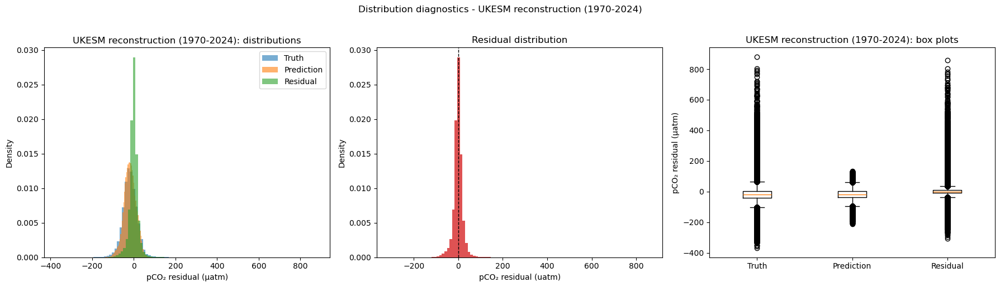

Saved figure to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_reconstruction_distribution_diagnostics.png


/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/244451621.py:88: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(


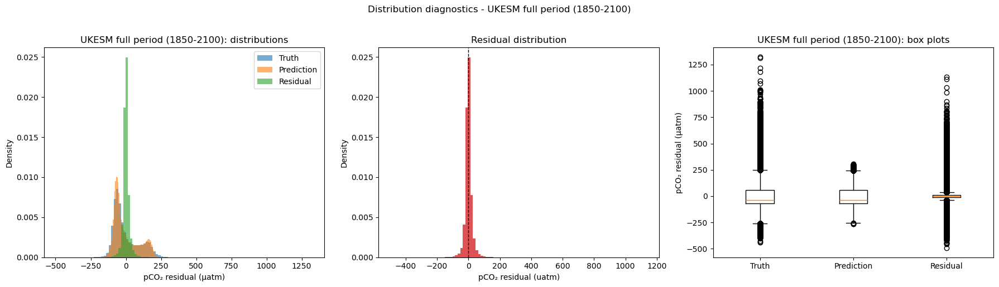

Saved figure to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_full_distribution_diagnostics.png


In [36]:
if RUN_MODE != "eval":
    plot_distribution_diagnostics(
        distributions=[val_true_flat, val_pred_flat, val_resid_flat],
        labels=["Truth", "Prediction", "Residual"],
        period_name="Validation",
        save_name="baseline_validation_distribution_diagnostics.png",
        panel2_data=val_resid_flat,
        panel2_title="Residual distribution",
        panel2_xlabel="pCO₂ residual (uatm)",
    )

plot_distribution_diagnostics(
    distributions=[test_recon_true_flat, test_recon_pred_flat, test_recon_resid_flat],
    labels=["Truth", "Prediction", "Residual"],
    period_name="UKESM reconstruction (1970-2024)",
    save_name="baseline_reconstruction_distribution_diagnostics.png",
    panel2_data=test_recon_resid_flat,
    panel2_title="Residual distribution",
    panel2_xlabel="pCO₂ residual (uatm)",
)

plot_distribution_diagnostics(
    distributions=[test_full_true_flat, test_full_pred_flat, test_full_resid_flat],
    labels=["Truth", "Prediction", "Residual"],
    period_name="UKESM full period (1850-2100)",
    save_name="baseline_full_distribution_diagnostics.png",
    panel2_data=test_full_resid_flat,
    panel2_title="Residual distribution",
    panel2_xlabel="pCO₂ residual (uatm)",
)

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/57563345.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(box_data, labels=["Satellite full", "Satellite overlap"], showfliers=True, vert=True)


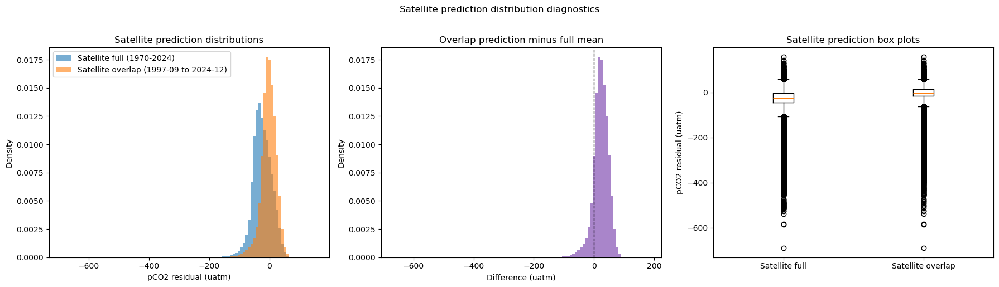

Saved satellite distribution comparison to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_satellite_distribution_comparison_full_vs_overlap.png


In [37]:
def plot_satellite_distribution_comparison(pred_flat_full, pred_flat_overlap, save_name):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    bins = 100

    axes[0].hist(pred_flat_full, bins=bins, alpha=0.6, density=True, label="Satellite full (1970-2024)")
    axes[0].hist(pred_flat_overlap, bins=bins, alpha=0.6, density=True, label="Satellite overlap (1997-09 to 2024-12)")
    axes[0].set_title("Satellite prediction distributions")
    axes[0].set_xlabel("pCO2 residual (uatm)")
    axes[0].set_ylabel("Density")
    axes[0].legend()

    diff = pred_flat_overlap - np.mean(pred_flat_full)
    axes[1].hist(diff[np.isfinite(diff)], bins=bins, alpha=0.8, color="tab:purple", density=True)
    axes[1].axvline(0.0, color="k", linestyle="--", linewidth=1)
    axes[1].set_title("Overlap prediction minus full mean")
    axes[1].set_xlabel("Difference (uatm)")
    axes[1].set_ylabel("Density")

    box_data = [
        pred_flat_full[np.isfinite(pred_flat_full)],
        pred_flat_overlap[np.isfinite(pred_flat_overlap)],
    ]
    axes[2].boxplot(box_data, labels=["Satellite full", "Satellite overlap"], showfliers=True, vert=True)
    axes[2].set_title("Satellite prediction box plots")
    axes[2].set_ylabel("pCO2 residual (uatm)")

    plt.suptitle("Satellite prediction distribution diagnostics", y=1.02)
    plt.tight_layout()

    save_path = os.path.join(FIGURES_DIR, save_name)
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved satellite distribution comparison to: {save_path}")

if USE_SATELLITE:
    plot_satellite_distribution_comparison(
        sat_pred_flat_full,
        sat_pred_flat_overlap,
        "baseline_satellite_distribution_comparison_full_vs_overlap.png"
    )

### Mean map plot over given period (full, seasonal, monthly)

In [38]:
def get_season_mask(times, season):
    times = pd.to_datetime(times)
    season_months = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}
    return np.isin(times.month, season_months[season])

def get_month_mask(times, month):
    return pd.to_datetime(times).month == month

def find_extreme_outliers(arr, lats, lons, label, pct=99, top_n=15):
    finite_mask = np.isfinite(arr)
    vals = arr[finite_mask]

    if vals.size == 0:
        print(f"[{label}] no finite values, skipping outlier check")
        return None, None
    
    thresh = np.nanpercentile(np.abs(vals), pct)
    outlier_mask = finite_mask & (np.abs(arr) >= thresh)
    lat_idx, lon_idx = np.where(outlier_mask)

    outlier_records = []
    for i in range(len(lat_idx)):
        row = lat_idx[i]
        col = lon_idx[i]
        lat_value = lats[row]
        lon_value = lons[col]
        data_value = arr[row, col]
        abs_value = abs(data_value)
        outlier_records.append((abs_value, lat_value, lon_value, data_value))

    outlier_records.sort(reverse=True)

    print(f"\n[{label}] top {100-pct}% outliers (|value| >= {thresh:.2f}), n={len(outlier_records)}")

    for record in outlier_records[:top_n]:
        abs_value, lat_value, lon_value, data_value = record
        print(f"  lat={lat_value:7.2f} lon={lon_value:7.2f} value={data_value:8.2f}")

    return outlier_mask, thresh

In [39]:
def plot_mean_comparison_maps(
    array_a, land_mask_a, title_a,
    array_b, land_mask_b, title_b,
    lats, lons,
    suptitle,
    save_name,
    diff_title="Difference",
    diff_order="b_minus_a",       # "b_minus_a" or "a_minus_b"
    cbar_mode="Residual",
    diff_cbar_label="Difference (uatm)",
    cmap="RdBu_r",
    land_color="#d0d0d0",
    diff_symmetric=True,          # keep the diff panel centered at 0 or not
    label_a="A",
    label_b="B",
    time_a=None,
    time_b=None,
    mode="annual",       # "annual", "season", "month"
    season=None,         # "DJF", "MAM", "JJA", "SON"
    month=None,          # 1-12
    outlier_pct=98,      # top (100-pct)% by |value| flagged as outliers
):
    if mode == "season":
        if season is None:
            raise ValueError("season must be specified when mode='season'")
        mask_a = get_season_mask(time_a, season)
        mask_b = get_season_mask(time_b, season)
        array_a = array_a[mask_a]
        land_mask_a = land_mask_a[mask_a]
        array_b = array_b[mask_b]
        land_mask_b = land_mask_b[mask_b]
    elif mode == "month":
        if month is None:
            raise ValueError("month must be specified when mode='month'")
        mask_a = get_month_mask(time_a, month)
        mask_b = get_month_mask(time_b, month)
        array_a = array_a[mask_a]
        land_mask_a = land_mask_a[mask_a]
        array_b = array_b[mask_b]
        land_mask_b = land_mask_b[mask_b]
    elif mode != "annual":
        raise ValueError(f"Unknown mode: {mode}")

    mean_a = np.asarray(masked_mean_map(array_a, land_mask_a)).squeeze()
    mean_b = np.asarray(masked_mean_map(array_b, land_mask_b)).squeeze()

    if diff_order == "b_minus_a":
        diff_mean = mean_b - mean_a
    else:
        diff_mean = mean_a - mean_b

    lats = np.asarray(lats).squeeze()
    lons = np.asarray(lons).squeeze()

    for name, arr in [("mean_a", mean_a), ("mean_b", mean_b), ("diff_mean", diff_mean)]:
        if arr.ndim != 2:
            raise ValueError(f"{name} must be 2D (lat, lon), got shape {arr.shape}")

    expected_shape = (len(lats), len(lons))
    if mean_a.shape != expected_shape:
        raise ValueError(
            f"Map shape {mean_a.shape} does not match (len(lats), len(lons))={expected_shape}"
        )

    outlier_mask_a, thresh_a = find_extreme_outliers(mean_a, lats, lons, f"{label_a} ({suptitle})", pct=outlier_pct)
    outlier_mask_b, thresh_b = find_extreme_outliers(mean_b, lats, lons, f"{label_b} ({suptitle})", pct=outlier_pct)
    outlier_mask_diff, thresh_diff = find_extreme_outliers(diff_mean, lats, lons, f"diff ({suptitle})", pct=outlier_pct)

    combined_outlier_mask = outlier_mask_a | outlier_mask_b | outlier_mask_diff
    outlier_display = np.where(combined_outlier_mask, diff_mean, np.nan)
    n_outliers = int(np.sum(combined_outlier_mask))
    print(f"\nTotal combined outlier pixels across A/B/diff: {n_outliers}")

    def data_range(arr, pmin=2, pmax=98):
        finite = arr[np.isfinite(arr)]
        # return np.nanmin(finite), np.nanmax(finite)
        return np.nanpercentile(finite, pmin), np.nanpercentile(finite, pmax)

    a_vmin, a_vmax = data_range(mean_a)
    b_vmin, b_vmax = data_range(mean_b)

    if diff_symmetric:
        dabs = np.nanmax(np.abs(diff_mean[np.isfinite(diff_mean)]))
        d_vmin, d_vmax = -dabs, dabs
    else:
        d_vmin, d_vmax = data_range(diff_mean)

    # fig, axes = plt.subplots(1, 3, figsize=(24, 7), subplot_kw={"projection": ccrs.Robinson()})
    # 4-panel with A, B, diff + outlier map
    fig, axes = plt.subplots(1, 4, figsize=(30, 7), subplot_kw={"projection": ccrs.Robinson()})

    cbar_label = cbar_mode + " pCO2 (uatm)"
    plot_specs = [
        (mean_a, title_a, cmap, a_vmin, a_vmax, cbar_label),
        (mean_b, title_b, cmap, b_vmin, b_vmax, cbar_label),
        (diff_mean, diff_title, cmap, d_vmin, d_vmax, diff_cbar_label),
    ]

    for ax, (data, title, cm, vmin, vmax, cbar_label_i) in zip(axes[:3], plot_specs):
        im = ax.pcolormesh(
            lons, lats, data,
            transform=ccrs.PlateCarree(),
            cmap=cm, vmin=vmin, vmax=vmax,
            shading="auto",
        )
        ax.add_feature(cfeature.LAND, color=land_color, zorder=3)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
        ax.set_title(title, fontsize=12)
        plt.colorbar(im, ax=ax, shrink=0.68, pad=0.03, label=cbar_label_i)

    # 4th = outlier locations coloured by diff value - everything else greyed out
    ax_out = axes[3]
    ax_out.pcolormesh(
        lons, lats, np.zeros_like(diff_mean),
        transform=ccrs.PlateCarree(),
        cmap="Greys", vmin=0, vmax=1, shading="auto", alpha=0.15,
    )
    im_out = ax_out.pcolormesh(
        lons, lats, outlier_display,
        transform=ccrs.PlateCarree(),
        cmap=cmap, vmin=d_vmin, vmax=d_vmax,
        shading="auto",
    )
    ax_out.add_feature(cfeature.LAND, color=land_color, zorder=3)
    ax_out.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
    ax_out.set_title(f"Outlier pixels (top {100-outlier_pct}%, n={n_outliers})", fontsize=12)
    plt.colorbar(im_out, ax=ax_out, shrink=0.68, pad=0.03, label=diff_cbar_label)

    plt.suptitle(suptitle, y=1.03, fontsize=15)
    plt.tight_layout()

    if save_name is not None:
        save_path = os.path.join(FIGURES_DIR, save_name)
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved mean map to: {save_path}")
    plt.show()

    print(f"{label_a} mean range: {np.nanmin(mean_a):.3f} to {np.nanmax(mean_a):.3f} uatm")
    print(f"{label_b} mean range: {np.nanmin(mean_b):.3f} to {np.nanmax(mean_b):.3f} uatm")
    print(f"Mean absolute difference: {np.nanmean(np.abs(diff_mean)):.3f} uatm")

### 1. Full period mean maps

#### CMIP6 truth vs prediction (residual pCO2)

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Truth (Baseline model mean maps - CMIP 1970-2024 (residual))] top 2% outliers (|value| >= 7.14), n=826
  lat=  38.50 lon= 121.50 value=  -26.54
  lat=  38.50 lon= 118.50 value=  -26.30
  lat=  38.50 lon= 122.50 value=  -22.35
  lat=  37.50 lon= 121.50 value=  -21.83
  lat=  37.50 lon= 122.50 value=  -21.18
  lat=  39.50 lon= 120.50 value=  -20.48
  lat=  38.50 lon= 120.50 value=  -19.90
  lat=  34.50 lon= 125.50 value=  -19.16
  lat=  38.50 lon= 119.50 value=  -18.84
  lat=  45.50 lon=  36.50 value=  -18.53
  lat=  36.50 lon= 122.50 value=  -18.26
  lat=  36.50 lon= 125.50 value=  -18.21
  lat=  30.50 lon= 122.50 value=  -18.11
  lat=  46.50 lon= -63.50 value=  -17.73
  lat=  31.50 lon= 122.50 value=  -17.52

[Prediction (Baseline model mean maps - CMIP 1970-2024 (residual))] top 2% outliers (|value| >= 13.49), n=826
  lat= -75.50 lon= -27.50 value=   39.10
  lat= -35.50 lon= -54.50 value=  -36.11
  lat=  34.50 lon= 121.50 value=  -34.78
  lat=  34.50 lon= 122.50 value=  -34.39
  lat

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_resid_cmip_mean_map_1970_2024.png


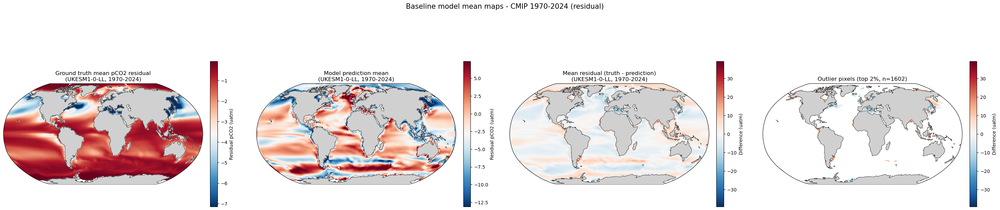

Truth mean range: -26.537 to -0.002 uatm
Prediction mean range: -36.113 to 39.100 uatm
Mean absolute difference: 3.724 uatm


In [40]:
plot_mean_comparison_maps(
    test_full_true_resid, test_full_land_mask,
    f"Ground truth mean pCO2 residual\n({TEST_MODEL}, 1970-2024)",
    test_full_pred_resid, test_full_land_mask,
    f"Model prediction mean\n({TEST_MODEL}, 1970-2024)",
    lats, lons,
    "Baseline model mean maps - CMIP 1970-2024 (residual)",
    "baseline_pCO2_resid_cmip_mean_map_1970_2024.png",
    diff_title=f"Mean residual (truth - prediction)\n({TEST_MODEL}, 1970-2024)",
    diff_order="a_minus_b",
    cbar_mode="Residual",
    label_a="Truth", label_b="Prediction",
    mode="annual"
)

#### CMIP6 truth vs prediction (total pCO2)

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Truth (Baseline model mean maps - CMIP 1970-2024 (total pCO2))] top 2% outliers (|value| >= 452.78), n=826
  lat= -36.50 lon= -73.50 value=  695.02
  lat= -35.50 lon= -73.50 value=  682.73
  lat= -35.50 lon= -74.50 value=  678.82
  lat= -37.50 lon= -73.50 value=  677.70
  lat= -34.50 lon= -74.50 value=  670.76
  lat= -34.50 lon= -73.50 value=  661.88
  lat= -36.50 lon= -74.50 value=  658.42
  lat= -33.50 lon= -74.50 value=  654.45
  lat= -33.50 lon= -73.50 value=  649.87
  lat= -32.50 lon= -74.50 value=  642.52
  lat= -34.50 lon= -72.50 value=  642.42
  lat= -38.50 lon= -73.50 value=  640.45
  lat= -31.50 lon= -74.50 value=  637.04
  lat= -32.50 lon= -73.50 value=  629.38
  lat= -33.50 lon= -72.50 value=  627.52

[Prediction (Baseline model mean maps - CMIP 1970-2024 (total pCO2))] top 2% outliers (|value| >= 452.18), n=826
  lat= -36.50 lon= -73.50 value=  691.47
  lat= -35.50 lon= -74.50 value=  684.72
  lat= -35.50 lon= -73.50 value=  678.78
  lat= -34.50 lon= -74.50 value=  678.4

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_total_cmip_mean_map_1970_2024.png


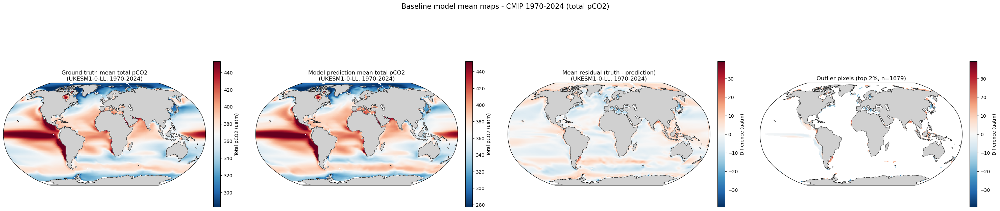

Truth mean range: 216.258 to 695.024 uatm
Prediction mean range: 206.907 to 691.474 uatm
Mean absolute difference: 3.724 uatm


In [41]:
plot_mean_comparison_maps(
    test_full_true_total, test_full_land_mask,
    f"Ground truth mean total pCO2\n({TEST_MODEL}, 1970-2024)",
    test_full_pred_total, test_full_land_mask,
    f"Model prediction mean total pCO2\n({TEST_MODEL}, 1970-2024)",
    lats, lons,
    "Baseline model mean maps - CMIP 1970-2024 (total pCO2)",
    "baseline_pCO2_total_cmip_mean_map_1970_2024.png",
    diff_title=f"Mean residual (truth - prediction)\n({TEST_MODEL}, 1970-2024)",
    diff_order="a_minus_b",
    cbar_mode="Total",
    label_a="Truth", label_b="Prediction",
    mode="annual"
)

#### Satellite vs CMIP6 predictions (residual pCO2)

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Satellite (Baseline model mean maps - satellite vs CMIP (residual pCO2))] top 2% outliers (|value| >= 69.04), n=786
  lat=  63.50 lon=-163.50 value= -349.39
  lat=  71.50 lon= 130.50 value= -230.88
  lat=  58.50 lon=  20.50 value= -213.72
  lat=  73.50 lon= 108.50 value= -212.38
  lat=  59.50 lon=  23.50 value= -206.97
  lat=  73.50 lon=  80.50 value= -206.49
  lat=  58.50 lon=  19.50 value= -204.12
  lat=  58.50 lon=  21.50 value= -204.06
  lat=  64.50 lon=  22.50 value= -200.35
  lat=  74.50 lon= 111.50 value= -197.86
  lat=  58.50 lon=  18.50 value= -194.08
  lat=  58.50 lon=  17.50 value= -189.20
  lat=  71.50 lon= 131.50 value= -187.75
  lat=  72.50 lon= 130.50 value= -184.66
  lat=  72.50 lon= 138.50 value= -184.57

[CMIP (Baseline model mean maps - satellite vs CMIP (residual pCO2))] top 2% outliers (|value| >= 13.49), n=826
  lat= -75.50 lon= -27.50 value=   39.10
  lat= -35.50 lon= -54.50 value=  -36.11
  lat=  34.50 lon= 121.50 value=  -34.78
  lat=  34.50 lon= 122.50 value

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_resid_sat_vs_cmip_mean_map_1970_2024.png


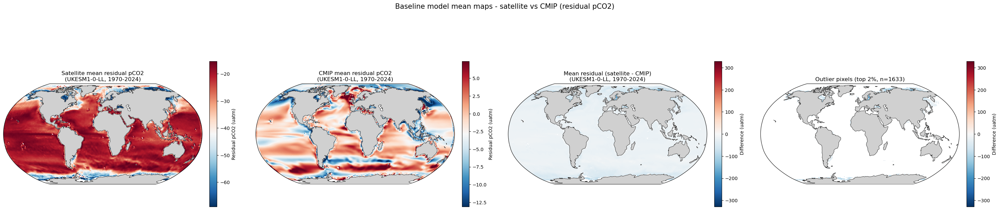

Satellite mean range: -349.385 to 1.224 uatm
CMIP mean range: -36.113 to 39.100 uatm
Mean absolute difference: 25.495 uatm


In [42]:
if USE_SATELLITE:
    # # Use lon from ds_sat for satellite plots
    # sat_lons = ds_sat.lon.values
    # sat_lats = ds_sat.lat.values
    # cmip_lats = ds.lat.values
    # cmip_lons = ds.lon.values

    # # should be same
    # assert np.array_equal(sat_lats, cmip_lats), "Satellite/CMIP lat grids differ"
    # assert np.array_equal(sat_lons, cmip_lons), "Satellite/CMIP lon grids differ"

    plot_mean_comparison_maps(
        sat_full_pred_resid, sat_full_land_mask,
        f"Satellite mean residual pCO2\n({TEST_MODEL}, 1970-2024)",
        test_full_pred_resid, test_full_land_mask,
        f"CMIP mean residual pCO2\n({TEST_MODEL}, 1970-2024)",
        sat_lats, sat_lons,
        "Baseline model mean maps - satellite vs CMIP (residual pCO2)",
        "baseline_pCO2_resid_sat_vs_cmip_mean_map_1970_2024.png",
        diff_title=f"Mean residual (satellite - CMIP)\n({TEST_MODEL}, 1970-2024)",
        diff_order="a_minus_b",
        cbar_mode="Residual",
        label_a="Satellite", label_b="CMIP",
        mode="annual",
    )

#### Satellite vs CMIP6 predictions (total pCO2)

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Satellite (Baseline model mean maps - satellite vs CMIP (total pCO2))] top 2% outliers (|value| >= 165.47), n=786
  lat=  63.50 lon=-163.50 value= -392.96
  lat=  71.50 lon= 130.50 value= -280.40
  lat=  64.50 lon=  22.50 value= -255.74
  lat=  73.50 lon= 108.50 value= -253.07
  lat=  73.50 lon=  80.50 value= -249.54
  lat=  58.50 lon=  20.50 value= -248.73
  lat=  59.50 lon=  23.50 value= -247.40
  lat=  63.50 lon=-165.50 value= -241.44
  lat=  58.50 lon=  19.50 value= -239.34
  lat=  74.50 lon= 111.50 value= -239.08
  lat=  58.50 lon=  21.50 value= -239.05
  lat=  71.50 lon= 131.50 value= -237.08
  lat=  69.50 lon=-136.50 value= -231.99
  lat=  58.50 lon=  18.50 value= -229.41
  lat=  65.50 lon=  24.50 value= -228.54

[CMIP (Baseline model mean maps - satellite vs CMIP (total pCO2))] top 2% outliers (|value| >= 452.18), n=826
  lat= -36.50 lon= -73.50 value=  691.47
  lat= -35.50 lon= -74.50 value=  684.72
  lat= -35.50 lon= -73.50 value=  678.78
  lat= -34.50 lon= -74.50 value=  6

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_total_sat_vs_cmip_mean_map_1970_2024.png


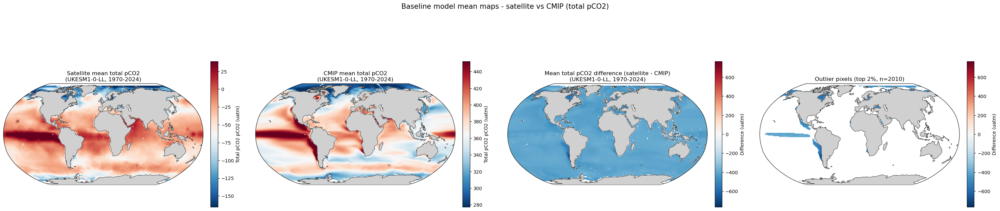

Satellite mean range: -392.963 to 91.985 uatm
CMIP mean range: 206.907 to 691.474 uatm
Mean absolute difference: 408.581 uatm


In [43]:
if USE_SATELLITE:
    plot_mean_comparison_maps(
        sat_full_pred_total_da, sat_full_land_mask,
        f"Satellite mean total pCO2\n({TEST_MODEL}, 1970-2024)",
        test_full_pred_total, test_full_land_mask,
        f"CMIP mean total pCO2\n({TEST_MODEL}, 1970-2024)",
        sat_lats, sat_lons,
        "Baseline model mean maps - satellite vs CMIP (total pCO2)",
        "baseline_pCO2_total_sat_vs_cmip_mean_map_1970_2024.png",
        diff_title=f"Mean total pCO2 difference (satellite - CMIP)\n({TEST_MODEL}, 1970-2024)",
        diff_order="a_minus_b",
        cbar_mode="Total pCO2",
        label_a="Satellite", label_b="CMIP",
        mode="annual",
    )

diagnostic - rmv

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CNN residual (Component breakdown - satellite total pCO2)] top 2% outliers (|value| >= 69.04), n=786
  lat=  63.50 lon=-163.50 value= -349.39
  lat=  71.50 lon= 130.50 value= -230.88
  lat=  58.50 lon=  20.50 value= -213.72
  lat=  73.50 lon= 108.50 value= -212.38
  lat=  59.50 lon=  23.50 value= -206.97
  lat=  73.50 lon=  80.50 value= -206.49
  lat=  58.50 lon=  19.50 value= -204.12
  lat=  58.50 lon=  21.50 value= -204.06
  lat=  64.50 lon=  22.50 value= -200.35
  lat=  74.50 lon= 111.50 value= -197.86
  lat=  58.50 lon=  18.50 value= -194.08
  lat=  58.50 lon=  17.50 value= -189.20
  lat=  71.50 lon= 131.50 value= -187.75
  lat=  72.50 lon= 130.50 value= -184.66
  lat=  72.50 lon= 138.50 value= -184.57

[Thermal term (Component breakdown - satellite total pCO2)] top 2% outliers (|value| >= 109.69), n=786
  lat=  82.50 lon= 161.50 value= -166.72
  lat=  82.50 lon= 110.50 value= -164.23
  lat=  82.50 lon= 147.50 value= -163.36
  lat=  82.50 lon= 157.50 value= -163.28
  lat=  82.50 

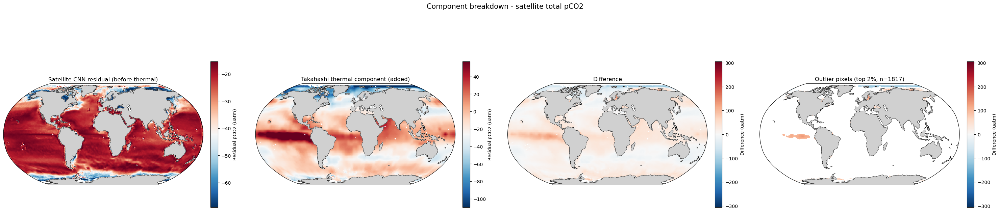

CNN residual mean range: -349.385 to 1.224 uatm
Thermal term mean range: -166.718 to 111.912 uatm
Mean absolute difference: 23.689 uatm


In [44]:
plot_mean_comparison_maps(
    sat_full_pred_resid, sat_full_land_mask,
    "Satellite CNN residual (before thermal)",
    pco2_thermal_full.values, sat_full_land_mask,
    "Takahashi thermal component (added)",
    sat_lats, sat_lons,
    "Component breakdown - satellite total pCO2",
    save_name=None,
    cbar_mode="Residual",
    label_a="CNN residual", label_b="Thermal term",
    mode="annual",
)

### 2. Seasonal mean maps (WI, SP, SU, FA)

In [45]:
seasons = ["DJF", "MAM", "JJA", "SON"]

#### CMIP6 truth vs prediction (residual pCO2)


[Truth (Baseline model seasonal mean maps - DJF (1970-2024, residual))] top 2% outliers (|value| >= 58.26), n=826
  lat=  57.50 lon= 144.50 value=  149.73
  lat=  57.50 lon= 143.50 value=  145.31
  lat=  56.50 lon= 143.50 value=  145.20
  lat=  69.50 lon= -81.50 value=  144.46
  lat= -13.50 lon= -80.50 value= -142.91
  lat=  56.50 lon= 144.50 value=  140.86
  lat=  57.50 lon= 145.50 value=  140.61
  lat= -14.50 lon= -80.50 value= -137.87
  lat=  56.50 lon= 142.50 value=  137.02
  lat= -14.50 lon= -79.50 value= -135.55
  lat= -38.50 lon= -73.50 value= -135.17
  lat=  58.50 lon= 144.50 value=  132.49
  lat= -13.50 lon= -79.50 value= -131.04
  lat=  57.50 lon= 142.50 value=  130.64
  lat=  69.50 lon= -80.50 value=  130.28

[Prediction (Baseline model seasonal mean maps - DJF (1970-2024, residual))] top 2% outliers (|value| >= 67.41), n=826
  lat= -67.50 lon=  30.50 value=  -84.36
  lat= -74.50 lon=-106.50 value=  -83.11
  lat= -72.50 lon=-119.50 value=  -82.18
  lat= -72.50 lon=-121.50 v

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_DJF_1970_2024.png


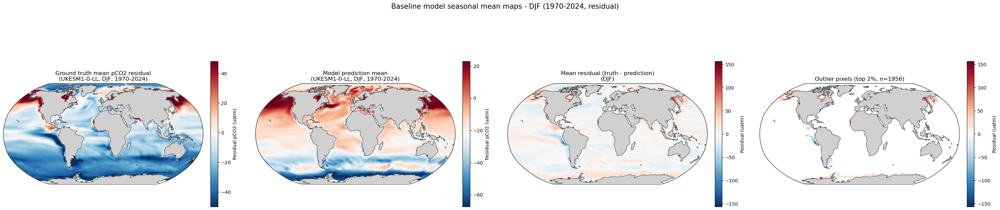

Truth mean range: -142.912 to 149.734 uatm
Prediction mean range: -84.358 to 66.219 uatm
Mean absolute difference: 10.021 uatm

[Truth (Baseline model seasonal mean maps - MAM (1970-2024, residual))] top 2% outliers (|value| >= 59.23), n=826
  lat=  61.50 lon= -92.50 value=  227.22
  lat=  61.50 lon= -91.50 value=  219.42
  lat=  62.50 lon= -91.50 value=  214.16
  lat=  60.50 lon= -91.50 value=  211.26
  lat=  63.50 lon= -89.50 value=  208.79
  lat=  60.50 lon= -92.50 value=  205.59
  lat=  62.50 lon= -90.50 value=  203.60
  lat=  60.50 lon= -90.50 value=  198.08
  lat=  61.50 lon= -90.50 value=  192.16
  lat=  62.50 lon= -92.50 value=  191.90
  lat=  63.50 lon= -88.50 value=  189.39
  lat=  60.50 lon= -93.50 value=  178.43
  lat=  60.50 lon= -89.50 value=  176.88
  lat=  62.50 lon= -89.50 value=  176.75
  lat=  61.50 lon= -89.50 value=  163.68

[Prediction (Baseline model seasonal mean maps - MAM (1970-2024, residual))] top 2% outliers (|value| >= 35.22), n=826
  lat=  21.50 lon= -17.

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_MAM_1970_2024.png


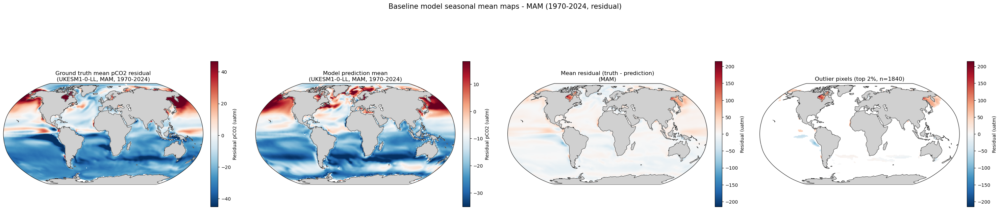

Truth mean range: -117.688 to 227.223 uatm
Prediction mean range: -60.545 to 60.084 uatm
Mean absolute difference: 9.663 uatm

[Truth (Baseline model seasonal mean maps - JJA (1970-2024, residual))] top 2% outliers (|value| >= 90.52), n=826
  lat=  69.50 lon= -81.50 value= -180.51
  lat=  67.50 lon= -80.50 value= -177.87
  lat=  61.50 lon= -92.50 value= -175.46
  lat=  68.50 lon= -80.50 value= -175.31
  lat=  69.50 lon= -80.50 value= -173.17
  lat=  69.50 lon= -79.50 value= -170.56
  lat=  60.50 lon= -92.50 value= -170.49
  lat= -13.50 lon= -80.50 value=  169.27
  lat=  60.50 lon= -93.50 value= -168.74
  lat=  62.50 lon= -92.50 value= -166.73
  lat=  69.50 lon= -78.50 value= -165.81
  lat= -38.50 lon= -73.50 value=  165.15
  lat=  62.50 lon= -91.50 value= -163.66
  lat=  69.50 lon=-101.50 value= -163.50
  lat= -14.50 lon= -80.50 value=  163.37

[Prediction (Baseline model seasonal mean maps - JJA (1970-2024, residual))] top 2% outliers (|value| >= 74.08), n=826
  lat=  71.50 lon= 154.5

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_JJA_1970_2024.png


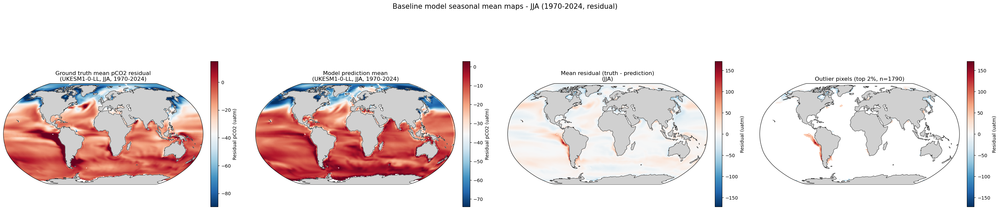

Truth mean range: -180.511 to 169.272 uatm
Prediction mean range: -116.093 to 59.224 uatm
Mean absolute difference: 8.753 uatm

[Truth (Baseline model seasonal mean maps - SON (1970-2024, residual))] top 2% outliers (|value| >= 70.76), n=826
  lat=  60.50 lon= -91.50 value= -150.21
  lat=  60.50 lon= -92.50 value= -149.77
  lat=  63.50 lon= -89.50 value= -147.65
  lat=  62.50 lon= -91.50 value= -147.21
  lat=  60.50 lon= -90.50 value= -144.51
  lat=  62.50 lon= -92.50 value= -141.54
  lat=  59.50 lon= -91.50 value= -139.85
  lat=  59.50 lon= -90.50 value= -139.58
  lat=  62.50 lon= -90.50 value= -139.42
  lat=  61.50 lon= -92.50 value= -139.42
  lat=  59.50 lon= -89.50 value= -138.86
  lat=  61.50 lon= -91.50 value= -137.22
  lat=  60.50 lon= -93.50 value= -136.08
  lat=  60.50 lon= -89.50 value= -136.03
  lat=  57.50 lon= -83.50 value= -135.57

[Prediction (Baseline model seasonal mean maps - SON (1970-2024, residual))] top 2% outliers (|value| >= 42.25), n=826
  lat=  34.50 lon= 122.

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_SON_1970_2024.png


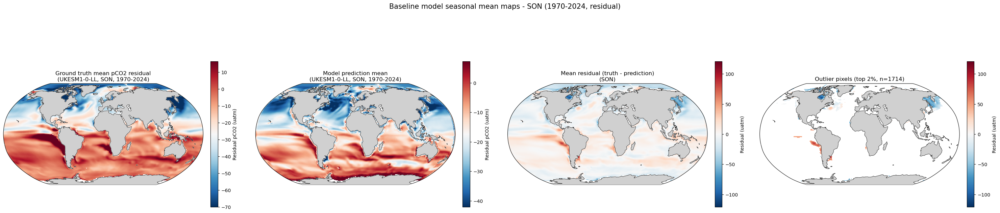

Truth mean range: -150.212 to 90.466 uatm
Prediction mean range: -101.901 to 65.696 uatm
Mean absolute difference: 11.580 uatm


In [46]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_true_resid, test_recon_land_mask,
        f"Ground truth mean pCO2 residual\n({TEST_MODEL}, {season}, 1970-2024)",
        test_recon_pred_resid, test_recon_land_mask,
        f"Model prediction mean\n({TEST_MODEL}, {season}, 1970-2024)",
        lats, lons,
        f"Baseline model seasonal mean maps - {season} (1970-2024, residual)",
        f"baseline_pCO2_res_cmip_{season}_1970_2024.png",
        diff_title=f"Mean residual (truth - prediction)\n({season})",
        diff_order="a_minus_b",
        diff_cbar_label="Residual (uatm)",
        label_a="Truth", label_b="Prediction",
        time_a=test_recon_time, time_b=test_recon_time,
        mode="season", season=season,
    )

#### CMIP6 truth vs prediction (total pCO2)


[Truth (Baseline model seasonal mean maps - DJF (1970-2024, total pCO2))] top 2% outliers (|value| >= 435.05), n=826
  lat= -35.50 lon= -73.50 value=  714.96
  lat= -35.50 lon= -74.50 value=  698.33
  lat= -36.50 lon= -73.50 value=  696.76
  lat= -34.50 lon= -72.50 value=  693.27
  lat= -34.50 lon= -73.50 value=  689.78
  lat= -34.50 lon= -74.50 value=  683.66
  lat= -33.50 lon= -72.50 value=  674.21
  lat= -33.50 lon= -73.50 value=  664.53
  lat= -32.50 lon= -72.50 value=  654.02
  lat= -33.50 lon= -74.50 value=  653.30
  lat= -36.50 lon= -74.50 value=  647.45
  lat= -32.50 lon= -73.50 value=  633.09
  lat= -31.50 lon= -72.50 value=  630.29
  lat= -32.50 lon= -74.50 value=  629.30
  lat= -37.50 lon= -73.50 value=  625.39

[Prediction (Baseline model seasonal mean maps - DJF (1970-2024, total pCO2))] top 2% outliers (|value| >= 426.95), n=826
  lat= -35.50 lon= -74.50 value=  700.18
  lat= -34.50 lon= -74.50 value=  692.01
  lat= -36.50 lon= -73.50 value=  690.83
  lat= -35.50 lon= -7

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_total_cmip_DJF_1970_2024.png


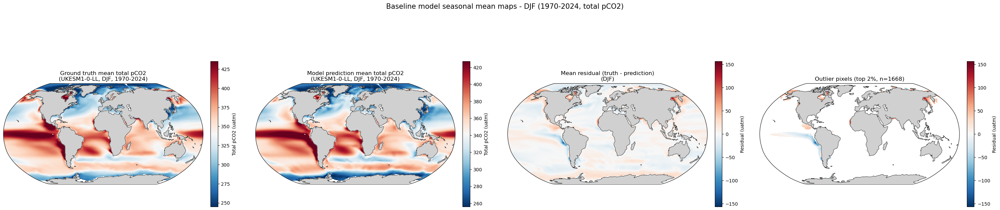

Truth mean range: 146.292 to 714.956 uatm
Prediction mean range: 196.317 to 700.183 uatm
Mean absolute difference: 10.021 uatm

[Truth (Baseline model seasonal mean maps - MAM (1970-2024, total pCO2))] top 2% outliers (|value| >= 441.72), n=826
  lat= -36.50 lon= -73.50 value=  760.22
  lat= -37.50 lon= -73.50 value=  752.44
  lat= -35.50 lon= -74.50 value=  739.65
  lat= -34.50 lon= -74.50 value=  724.82
  lat= -35.50 lon= -73.50 value=  721.77
  lat= -36.50 lon= -74.50 value=  711.24
  lat= -38.50 lon= -73.50 value=  708.91
  lat= -34.50 lon= -73.50 value=  693.83
  lat= -33.50 lon= -74.50 value=  686.92
  lat=  61.50 lon= -92.50 value=  678.31
  lat= -37.50 lon= -74.50 value=  668.06
  lat=  62.50 lon= -91.50 value=  664.56
  lat= -33.50 lon= -73.50 value=  664.38
  lat=  63.50 lon= -89.50 value=  661.08
  lat= -32.50 lon= -74.50 value=  653.38

[Prediction (Baseline model seasonal mean maps - MAM (1970-2024, total pCO2))] top 2% outliers (|value| >= 441.25), n=826
  lat= -36.50 lon

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_total_cmip_MAM_1970_2024.png


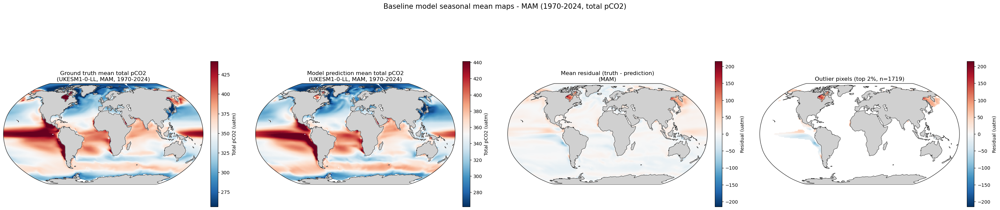

Truth mean range: 203.226 to 760.225 uatm
Prediction mean range: 196.750 to 675.408 uatm
Mean absolute difference: 9.663 uatm

[Truth (Baseline model seasonal mean maps - JJA (1970-2024, total pCO2))] top 2% outliers (|value| >= 439.71), n=826
  lat= -37.50 lon= -73.50 value=  775.89
  lat= -36.50 lon= -73.50 value=  770.04
  lat= -38.50 lon= -73.50 value=  744.75
  lat= -35.50 lon= -73.50 value=  733.62
  lat= -35.50 lon= -74.50 value=  712.47
  lat= -36.50 lon= -74.50 value=  707.23
  lat= -34.50 lon= -73.50 value=  706.93
  lat= -34.50 lon= -74.50 value=  697.34
  lat= -33.50 lon= -73.50 value=  687.63
  lat= -37.50 lon= -74.50 value=  679.21
  lat= -33.50 lon= -74.50 value=  677.74
  lat= -32.50 lon= -74.50 value=  670.03
  lat= -34.50 lon= -72.50 value=  665.70
  lat= -31.50 lon= -74.50 value=  665.35
  lat= -32.50 lon= -73.50 value=  664.97

[Prediction (Baseline model seasonal mean maps - JJA (1970-2024, total pCO2))] top 2% outliers (|value| >= 440.30), n=826
  lat= -36.50 lon=

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_total_cmip_JJA_1970_2024.png


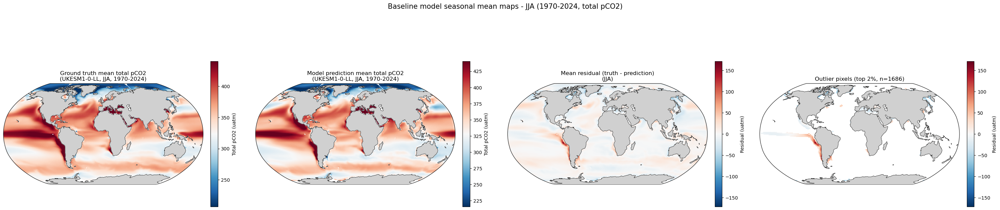

Truth mean range: 134.073 to 775.892 uatm
Prediction mean range: 120.105 to 630.233 uatm
Mean absolute difference: 8.753 uatm

[Truth (Baseline model seasonal mean maps - SON (1970-2024, total pCO2))] top 2% outliers (|value| >= 433.96), n=826
  lat= -31.50 lon= -74.50 value=  634.75
  lat= -30.50 lon= -74.50 value=  633.08
  lat= -31.50 lon= -73.50 value=  622.79
  lat= -32.50 lon= -73.50 value=  622.71
  lat= -32.50 lon= -74.50 value=  622.35
  lat= -33.50 lon= -73.50 value=  617.65
  lat= -23.50 lon= -70.50 value=  614.07
  lat= -22.50 lon= -70.50 value=  613.85
  lat= -35.50 lon= -73.50 value=  611.48
  lat= -24.50 lon= -70.50 value=  610.16
  lat= -33.50 lon= -74.50 value=  609.85
  lat= -30.50 lon= -73.50 value=  609.44
  lat= -21.50 lon= -70.50 value=  609.19
  lat= -34.50 lon= -73.50 value=  608.19
  lat= -32.50 lon= -72.50 value=  605.34

[Prediction (Baseline model seasonal mean maps - SON (1970-2024, total pCO2))] top 2% outliers (|value| >= 428.89), n=826
  lat= -35.50 lon=

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_total_cmip_SON_1970_2024.png


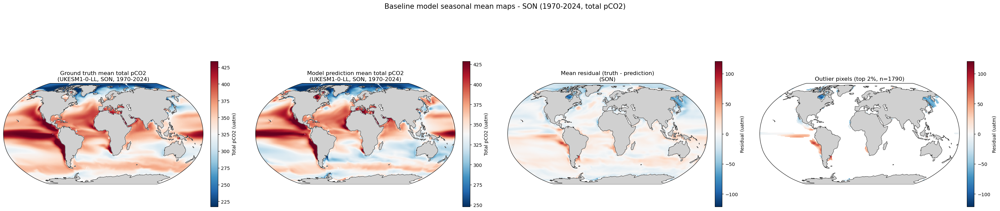

Truth mean range: 136.974 to 634.754 uatm
Prediction mean range: 170.769 to 645.837 uatm
Mean absolute difference: 11.580 uatm


In [47]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_true_total, test_recon_land_mask,
        f"Ground truth mean total pCO2\n({TEST_MODEL}, {season}, 1970-2024)",
        test_recon_pred_total, test_recon_land_mask,
        f"Model prediction mean total pCO2\n({TEST_MODEL}, {season}, 1970-2024)",
        lats, lons,
        f"Baseline model seasonal mean maps - {season} (1970-2024, total pCO2)",
        f"baseline_pCO2_total_cmip_{season}_1970_2024.png",
        diff_title=f"Mean residual (truth - prediction)\n({season})",
        diff_order="a_minus_b",
        cbar_mode="Total",
        diff_cbar_label="Residual (uatm)",
        label_a="Truth", label_b="Prediction",
        time_a=test_recon_time, time_b=test_recon_time,
        mode="season", season=season,
    )

#### Satellite vs CMIP6 predictions (residual pCO2)


[CMIP (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 67.41), n=826
  lat= -67.50 lon=  30.50 value=  -84.36
  lat= -74.50 lon=-106.50 value=  -83.11
  lat= -72.50 lon=-119.50 value=  -82.18
  lat= -72.50 lon=-121.50 value=  -81.82
  lat= -67.50 lon=  31.50 value=  -81.76
  lat= -68.50 lon=  25.50 value=  -81.31
  lat= -72.50 lon=-122.50 value=  -81.17
  lat= -65.50 lon=  82.50 value=  -81.14
  lat= -66.50 lon=  79.50 value=  -80.97
  lat= -68.50 lon=  26.50 value=  -80.93
  lat= -66.50 lon=  78.50 value=  -80.63
  lat= -67.50 lon=  29.50 value=  -80.61
  lat= -72.50 lon= -22.50 value=  -80.57
  lat= -71.50 lon= -86.50 value=  -80.53
  lat= -71.50 lon= -85.50 value=  -80.53

[Satellite (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 68.85), n=717
  lat= -74.50 lon= -43.50 value= -118.24
  lat= -74.50 lon= -49.50 value= -114.17
  lat= -50.50 lon= -60.50 value= -112.75
  lat= -74.50 lon= -41.50 value= -110.40
  lat= -76.50 lon= 169.50 

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_DJF_1970_2024.png


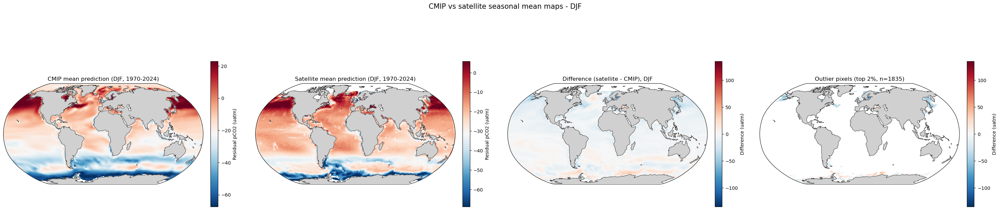

CMIP mean range: -84.358 to 66.219 uatm
Satellite mean range: -118.244 to 39.794 uatm
Mean absolute difference: 7.506 uatm

[CMIP (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 35.22), n=826
  lat=  21.50 lon= -17.50 value=  -60.55
  lat=  61.50 lon=  19.50 value=   60.08
  lat= -25.50 lon=  13.50 value=  -58.60
  lat=  60.50 lon=  19.50 value=   56.99
  lat=  61.50 lon=  20.50 value=   56.71
  lat=  19.50 lon= -16.50 value=  -56.34
  lat=  60.50 lon=  20.50 value=   55.79
  lat=  17.50 lon= -16.50 value=  -54.86
  lat=  62.50 lon=  19.50 value=   54.34
  lat=  61.50 lon=  18.50 value=   54.19
  lat=  59.50 lon=  20.50 value=   52.95
  lat=  59.50 lon=  19.50 value=   52.53
  lat= -24.50 lon=  13.50 value=  -52.43
  lat=  20.50 lon= -17.50 value=  -52.17
  lat= -25.50 lon=  14.50 value=  -51.10

[Satellite (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 51.74), n=754
  lat=  59.50 lon=  23.50 value= -174.89
  lat=   0.50 lon= -49.50 

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_MAM_1970_2024.png


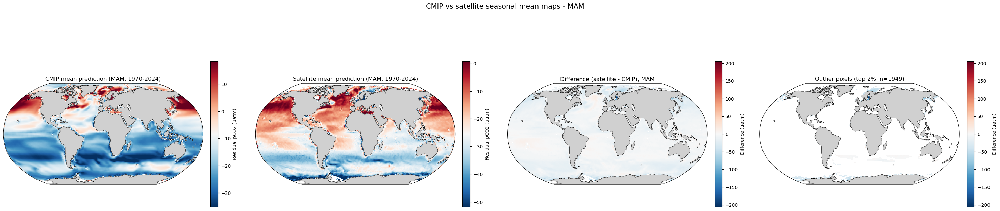

CMIP mean range: -60.545 to 60.084 uatm
Satellite mean range: -174.895 to 20.470 uatm
Mean absolute difference: 9.680 uatm

[CMIP (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 74.08), n=826
  lat=  71.50 lon= 154.50 value= -116.09
  lat=  73.50 lon= 120.50 value= -115.51
  lat=  73.50 lon= 142.50 value= -114.11
  lat=  74.50 lon= 144.50 value= -113.01
  lat=  74.50 lon= 143.50 value= -112.43
  lat=  73.50 lon= 141.50 value= -111.39
  lat=  73.50 lon= 139.50 value= -110.56
  lat=  73.50 lon= 140.50 value= -109.73
  lat=  56.50 lon=  18.50 value= -109.35
  lat=  53.50 lon= -80.50 value= -108.01
  lat=  71.50 lon= 153.50 value= -107.95
  lat=  74.50 lon= 145.50 value= -107.72
  lat=  74.50 lon= 140.50 value= -107.65
  lat=  33.50 lon= 122.50 value= -105.47
  lat=  57.50 lon=  19.50 value= -105.24

[Satellite (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 92.94), n=724
  lat=  63.50 lon=-163.50 value= -476.92
  lat=  58.50 lon=  21.50 

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_JJA_1970_2024.png


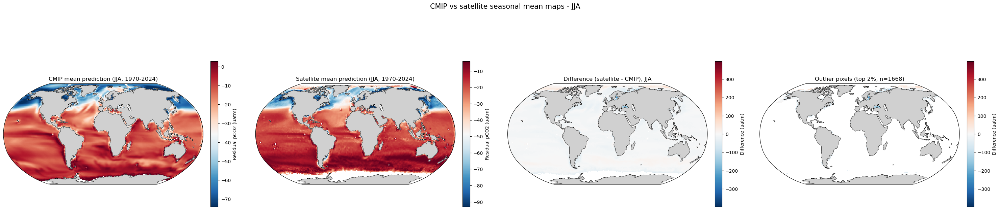

CMIP mean range: -116.093 to 59.224 uatm
Satellite mean range: -476.924 to 9.375 uatm
Mean absolute difference: 9.756 uatm

[CMIP (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 42.25), n=826
  lat=  34.50 lon= 122.50 value= -101.90
  lat=  33.50 lon= 122.50 value=  -94.62
  lat=  35.50 lon= 122.50 value=  -91.20
  lat=  33.50 lon= 123.50 value=  -87.49
  lat=  34.50 lon= 123.50 value=  -86.21
  lat=  34.50 lon= 121.50 value=  -86.06
  lat=  33.50 lon= 121.50 value=  -81.97
  lat=  35.50 lon= 121.50 value=  -80.68
  lat=  53.50 lon= -80.50 value=  -80.04
  lat=  36.50 lon= 122.50 value=  -78.58
  lat=  32.50 lon= 122.50 value=  -77.13
  lat=  35.50 lon= 123.50 value=  -76.72
  lat=  52.50 lon= -80.50 value=  -73.03
  lat=  40.50 lon= -60.50 value=  -71.79
  lat=  40.50 lon= -59.50 value=  -71.35

[Satellite (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 81.09), n=773
  lat=  63.50 lon=-163.50 value= -386.52
  lat=  64.50 lon=  22.50 

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_SON_1970_2024.png


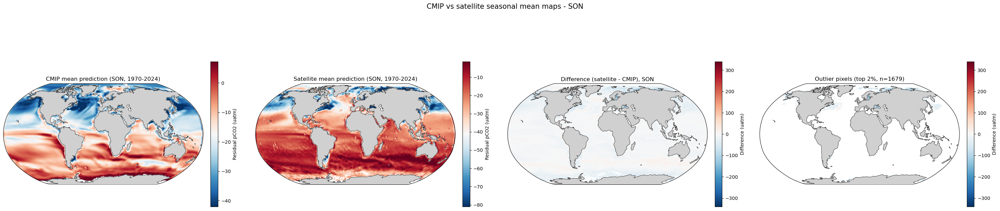

CMIP mean range: -101.901 to 65.696 uatm
Satellite mean range: -386.521 to 9.214 uatm
Mean absolute difference: 11.670 uatm


In [48]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_pred_resid, test_recon_land_mask,
        f"CMIP mean prediction ({season}, 1970-2024)",
        sat_full_pred_resid, sat_full_land_mask,
        f"Satellite mean prediction ({season}, 1970-2024)",
        lats, lons,
        f"CMIP vs satellite seasonal mean maps - {season}",
        f"baseline_pCO2_res_cmip_vs_satellite_{season}_1970_2024.png",
        diff_title=f"Difference (satellite - CMIP), {season}",
        diff_order="b_minus_a",
        label_a="CMIP", label_b="Satellite",
        time_a=test_recon_time, time_b=sat_full_time,
        mode="season", season=season,
    )

#### Satellite vs CMIP6 predictions (total pCO2)

/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 426.95), n=826
  lat= -35.50 lon= -74.50 value=  700.18
  lat= -34.50 lon= -74.50 value=  692.01
  lat= -36.50 lon= -73.50 value=  690.83
  lat= -35.50 lon= -73.50 value=  687.26
  lat= -37.50 lon= -73.50 value=  674.24
  lat= -36.50 lon= -74.50 value=  673.47
  lat= -33.50 lon= -74.50 value=  671.43
  lat= -34.50 lon= -72.50 value=  662.80
  lat= -34.50 lon= -73.50 value=  658.40
  lat= -38.50 lon= -73.50 value=  653.56
  lat= -32.50 lon= -74.50 value=  652.54
  lat= -31.50 lon= -74.50 value=  646.78
  lat= -33.50 lon= -73.50 value=  643.52
  lat= -33.50 lon= -72.50 value=  642.02
  lat= -37.50 lon= -74.50 value=  640.11

[Satellite (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 106.23), n=717
  lat= -76.50 lon= 169.50 value= -195.04
  lat= -76.50 lon= 168.50 value= -192.11
  lat= -76.50 lon= 170.50 value= -188.37
  lat= -76.50 lon= 171.50 value= -187.73
  lat= -76.50 lon= 167.5

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_DJF_1970_2024.png


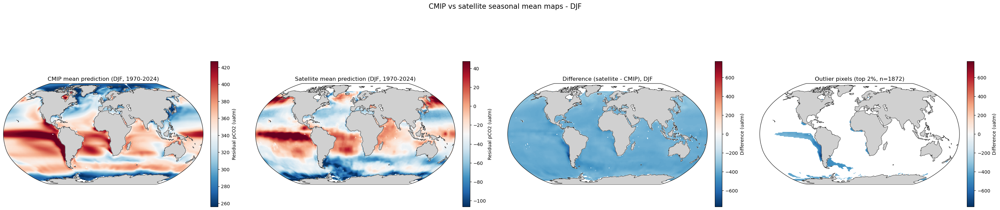

CMIP mean range: 196.317 to 700.183 uatm
Satellite mean range: -195.035 to 92.461 uatm
Mean absolute difference: 381.593 uatm


/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 441.25), n=826
  lat= -36.50 lon= -73.50 value=  675.41
  lat= -35.50 lon= -74.50 value=  673.14
  lat= -34.50 lon= -74.50 value=  666.25
  lat= -35.50 lon= -73.50 value=  665.00
  lat= -36.50 lon= -74.50 value=  650.40
  lat= -37.50 lon= -73.50 value=  650.32
  lat= -33.50 lon= -74.50 value=  650.25
  lat= -32.50 lon= -74.50 value=  634.20
  lat= -34.50 lon= -73.50 value=  631.73
  lat= -31.50 lon= -74.50 value=  629.26
  lat= -33.50 lon= -73.50 value=  621.33
  lat= -34.50 lon= -72.50 value=  616.15
  lat= -38.50 lon= -73.50 value=  614.96
  lat= -37.50 lon= -74.50 value=  614.90
  lat= -30.50 lon= -74.50 value=  611.67

[Satellite (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 98.78), n=754
  lat=  59.50 lon=  23.50 value= -234.23
  lat=  58.50 lon=  19.50 value= -216.22
  lat=  58.50 lon=  20.50 value= -211.61
  lat=  58.50 lon=  18.50 value= -203.26
  lat=  82.50 lon=  83.50

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_MAM_1970_2024.png


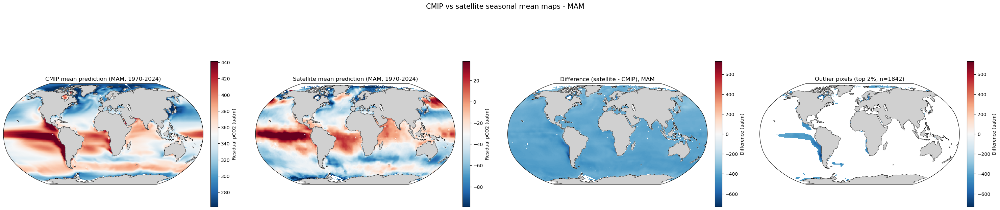

CMIP mean range: 196.750 to 675.408 uatm
Satellite mean range: -234.230 to 89.397 uatm
Mean absolute difference: 384.560 uatm


/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 440.30), n=826
  lat= -36.50 lon= -73.50 value=  630.23
  lat= -35.50 lon= -74.50 value=  625.89
  lat= -37.50 lon= -73.50 value=  620.58
  lat= -34.50 lon= -74.50 value=  620.36
  lat= -33.50 lon= -74.50 value=  613.07
  lat= -36.50 lon= -74.50 value=  610.22
  lat= -35.50 lon= -73.50 value=  606.82
  lat= -32.50 lon= -74.50 value=  599.56
  lat= -34.50 lon= -73.50 value=  596.87
  lat= -31.50 lon= -74.50 value=  594.87
  lat= -33.50 lon= -73.50 value=  592.01
  lat= -37.50 lon= -74.50 value=  578.11
  lat= -30.50 lon= -74.50 value=  574.11
  lat= -38.50 lon= -73.50 value=  573.73
  lat= -32.50 lon= -73.50 value=  571.13

[Satellite (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 194.46), n=724
  lat=  63.50 lon=-163.50 value= -577.14
  lat=  58.50 lon=  21.50 value= -398.62
  lat=  58.50 lon=  20.50 value= -395.48
  lat=  63.50 lon=-165.50 value= -393.88
  lat=  59.50 lon=  23.5

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_JJA_1970_2024.png


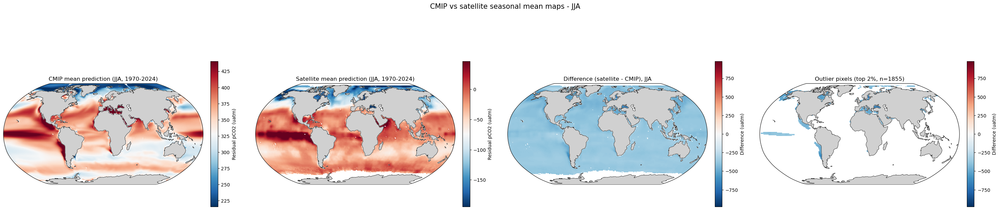

CMIP mean range: 120.105 to 630.233 uatm
Satellite mean range: -577.144 to 103.758 uatm
Mean absolute difference: 386.089 uatm


/var/tmp/pbs.3696396.pbs-7/ipykernel_4055068/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 428.89), n=826
  lat= -35.50 lon= -74.50 value=  645.84
  lat= -34.50 lon= -74.50 value=  644.60
  lat= -36.50 lon= -73.50 value=  642.97
  lat= -35.50 lon= -73.50 value=  637.08
  lat= -34.50 lon= -73.50 value=  634.61
  lat= -33.50 lon= -74.50 value=  630.63
  lat= -37.50 lon= -73.50 value=  622.71
  lat= -33.50 lon= -73.50 value=  622.32
  lat= -36.50 lon= -74.50 value=  620.36
  lat= -32.50 lon= -74.50 value=  616.14
  lat= -31.50 lon= -74.50 value=  609.16
  lat= -32.50 lon= -73.50 value=  598.80
  lat= -34.50 lon= -72.50 value=  592.06
  lat= -30.50 lon= -74.50 value=  587.53
  lat= -37.50 lon= -74.50 value=  587.37

[Satellite (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 144.76), n=773
  lat=  63.50 lon=-163.50 value= -409.99
  lat=  64.50 lon=  22.50 value= -349.76
  lat=  64.50 lon=  23.50 value= -328.57
  lat=  65.50 lon=  23.50 value= -321.27
  lat=  72.50 lon=  74.5

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_pCO2_res_cmip_vs_satellite_SON_1970_2024.png


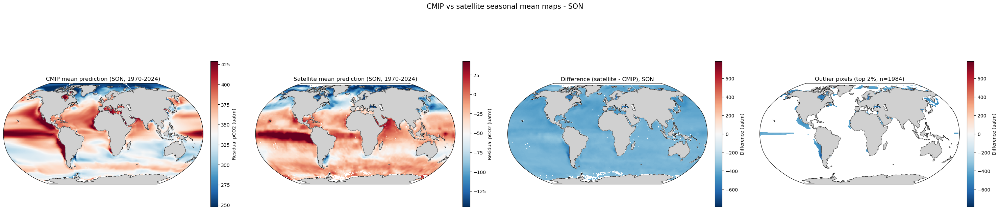

CMIP mean range: 170.769 to 645.837 uatm
Satellite mean range: -409.986 to 97.466 uatm
Mean absolute difference: 382.672 uatm


In [49]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_pred_total, test_recon_land_mask,
        f"CMIP mean prediction ({season}, 1970-2024)",
        sat_full_pred_total_da, sat_full_land_mask,
        f"Satellite mean prediction ({season}, 1970-2024)",
        lats, lons,
        f"CMIP vs satellite seasonal mean maps - {season}",
        f"baseline_pCO2_res_cmip_vs_satellite_{season}_1970_2024.png",
        diff_title=f"Difference (satellite - CMIP), {season}",
        diff_order="b_minus_a",
        label_a="CMIP", label_b="Satellite",
        time_a=test_recon_time, time_b=sat_full_time,
        mode="season", season=season,
    )

### 3. Monthly global ocean mean predicted pCO2 residual

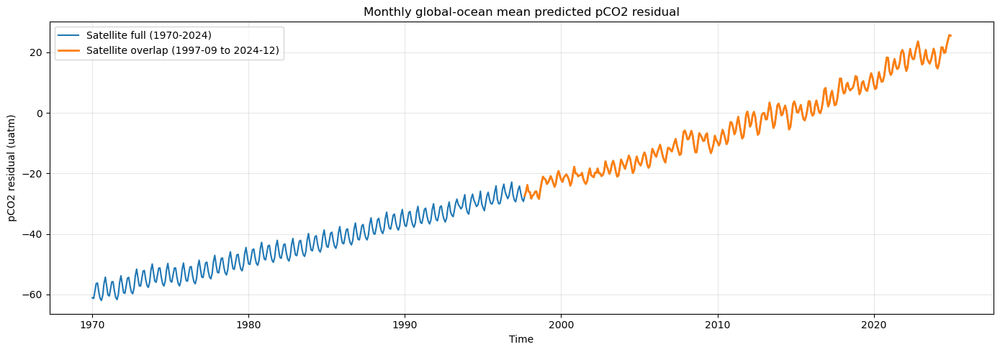

Saved satellite time-series plot to: /rds/general/user/efs25/home/irp-efs25/figures/baseline_satellite_monthly_mean_timeseries_full_vs_overlap.png
Full monthly mean range: -61.988197326660156 to 25.694917678833008
Overlap monthly mean range: -28.42635726928711 to 25.694917678833008


In [50]:
def monthly_ocean_mean(pred_resid, land_mask):
    ocean = ~land_mask[:, 0]
    means = []
    for t in range(pred_resid.shape[0]):
        vals = pred_resid[t, 0][ocean[t]]
        vals = vals[np.isfinite(vals)]
        means.append(np.nan if vals.size == 0 else vals.mean())
    return np.array(means, dtype=np.float32)

def plot_satellite_timeseries(time_full, pred_resid_full, land_mask_full,
                              time_overlap, pred_resid_overlap, land_mask_overlap,
                              save_name):
    mean_full = monthly_ocean_mean(pred_resid_full, land_mask_full)
    mean_overlap = monthly_ocean_mean(pred_resid_overlap, land_mask_overlap)

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(time_full, mean_full, label="Satellite full (1970-2024)", linewidth=1.5)
    ax.plot(time_overlap, mean_overlap, label="Satellite overlap (1997-09 to 2024-12)", linewidth=2.0)

    ax.set_title("Monthly global-ocean mean predicted pCO2 residual")
    ax.set_xlabel("Time")
    ax.set_ylabel("pCO2 residual (uatm)")
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    save_path = os.path.join(FIGURES_DIR, save_name)
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved satellite time-series plot to: {save_path}")
    print("Full monthly mean range:", float(np.nanmin(mean_full)), "to", float(np.nanmax(mean_full)))
    print("Overlap monthly mean range:", float(np.nanmin(mean_overlap)), "to", float(np.nanmax(mean_overlap)))

if USE_SATELLITE:
    plot_satellite_timeseries(
        sat_full_time,
        sat_full_pred_resid,
        sat_full_land_mask,
        sat_overlap_time,
        sat_overlap_pred_resid,
        sat_overlap_land_mask,
        "baseline_satellite_monthly_mean_timeseries_full_vs_overlap.png"
    )